# Практична робота № 5 — Багатокритеріальний вибір ML-моделі за інженерними обмеженнями

**Набір даних:** Breast Cancer Wisconsin (Diagnostic) (`sklearn.datasets.load_breast_cancer`), той самий спліт 80/20, що в попередніх роботах.
**Позитивний клас** $y=1$ — **злоякісне** новоутворення. **Варіант 5.**

**Мета.** Не «знайти найточнішу модель», а *вибрати модель під інженерний сценарій*: спершу відсіяти кандидатів за жорсткими обмеженнями
(recall, затримка, розмір), потім ранжувати допущених за зваженою сумою нормалізованих критеріїв; оформити вибір як відтворюваний інструмент
(`select_model.py` + JSON-конфігурації + модульні тести), перевірити стійкість вибору й один раз перевірити результат на тесті.

> **Логіка роботи:** контекст і обмеження → фіксовані кандидати → єдине CV-оцінювання й профілювання → обмеження → нормалізація й рейтинг →
> другий сценарій → чутливість → тести → фіксація рішення → одноразовий test.

> **Тест відкривається один раз — у розділі 13.** До цього використовується лише навчальна частина (455 об'єктів).

> **Про вимірювання часу.** Ноутбук **не запускає** benchmark: він читає закомічені `results/benchmark_results.csv`, `fold_results.csv`,
> `latency_samples.csv`, `experiment_metadata.json`, створені командою `python run_benchmark.py`. Числа часу (p50/p95, пропускна здатність, час навчання)
> залежать від машини й навантаження в момент запуску; числа якості (CV-метрики) й розмір файлів від машини практично не залежать.
> Тому всі числа в тексті відповідають закоміченим CSV, а не новому запуску.

> **Застереження.** Клінічний контекст нижче — гіпотетична навчальна постановка, а не медична рекомендація; усі межі й ваги — сценарні припущення.

In [1]:
import hashlib
import json
import subprocess
import sys
from copy import deepcopy

from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import binomtest
from sklearn.metrics import (balanced_accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)

ROOT = Path.cwd().parent                      # ноутбук виконується з каталогу notebook/
sys.path.insert(0, str(ROOT))

from src.candidates import CANDIDATES, THRESHOLD, describe_candidates, load_data, make_cv   # noqa: E402
from src.model_selector import (NoEligibleModelError, check_constraints, load_config,        # noqa: E402
                                normalize_value, rank_models, reweight, save_selection,
                                sensitivity_analysis)

RES = ROOT / "results"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.precision", 4)

plt.rcParams.update({"savefig.dpi": 120, "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

TEST_OPENED = False                            # прапорець: тест ще не відкрито (змінюється лише в розділі 13)
ORDER = list(CANDIDATES)                       # logreg, tree, knn, svm_rbf, random_forest, hist_gb
MC = {"logreg": "#0072B2", "tree": "#D55E00", "knn": "#009E73", "svm_rbf": "#CC79A7",
      "random_forest": "#E69F00", "hist_gb": "#56B4E9"}      # один колір на модель в усіх рисунках


def save_show(fig, name):
    # зберігає рисунок у figures/ (dpi = 120) і показує його в ноутбуці
    fig.savefig(FIG / name, dpi=120, bbox_inches="tight")
    plt.show()


print("ROOT =", ROOT)
print("TEST_OPENED =", TEST_OPENED)

ROOT = D:\ХНУ\3kurs\МашНавчання\machine-learning-course\practical05
TEST_OPENED = False


## 1. Інженерний контекст (завдання 1)

Усе нижче — **гіпотетичний навчальний сценарій** (дані публічні й навчальні). Вимоги сформульовано вимірювано: кожна «швидко / малого розміру / надійно»
перетворена на метрику й межу.

| Питання завдання | Відповідь |
|---|---|
| **Задача, target** | Бінарна класифікація зразка тонкоголкової аспірації (FNA): за 30 морфометричними ознаками клітинних ядер передбачити, чи злоякісне новоутворення. $y=1$ — злоякісне (у `sklearn` кодування протилежне, тому $y=1-\text{target}$), $y=0$ — доброякісне. |
| **Споживач прогнозу** | Програмне забезпечення **робочої станції цитолога**: одразу після сегментації ядер показує «підказку» (ймовірність злоякісності); вночі той самий модуль повторно прочитує всі зразки за день (друга думка). Остаточне рішення завжди за лікарем. |
| **Середовище виконання** | Ноутбучний CPU Intel Core i5-1035G1 @ 1.00 ГГц, Windows 11, Python 3.12.0, scikit-learn 1.9.0, **1 потік** (спільний процесор із іншим ПЗ станції) — усі виміри в `experiment_metadata.json`. |
| **Режим відповіді** | Сценарій 1: **синхронний**, пакет = 1 зразок. Сценарій 2: **пакетний** (нічний), пакети по 256 зразків. |
| **Ціна критичної помилки** | Найдорожча помилка — **пропуск злоякісного** (FN): хибне заспокоєння, затримка діагностики. Зайва тривога (FP) — додаткове обстеження, значно дешевша. Тому recall — **жорстка межа**, а не одна з рівноцінних метрик: $\text{recall}_{CV}\ge0{,}95$ в обох сценаріях. |
| **Обмеження сценарію 1** | $\text{recall}\ge0{,}95$; $p95$ часу `predict_proba` для 1 зразка $\le10$ мс; розмір серіалізованого pipeline $\le0{,}5$ МБ (модель постачається в пакеті оновлення ПЗ станції). |
| **Обмеження сценарію 2** | $\text{recall}\ge0{,}95$; $F_1\ge0{,}94$; $p95$ для пакета 256 $\le200$ мс; розмір $\le5$ МБ. Пріоритет — якість (ROC-AUC, $F_1$) і стабільність; затримка некритична. |
| **Умови перевибору** | Дрейф даних/пристрою (інший прилад, інший протокол фарбування); нова версія scikit-learn/Python; нове залізо (час залежить від машини); зміна ціни помилок або меж; поява нових кандидатів; нова навчальна вибірка; суттєва зміна recall у моніторингу. Повний список — у розділі 12. |

*Усі межі (0,95; 10 мс; 0,5 МБ; 200 мс; 5 МБ) — сценарні припущення навчального завдання; у реальному проєкті їх треба узгоджувати з клініцистами й інженерами станції.*

In [2]:
meta = json.loads((RES / "experiment_metadata.json").read_text(encoding="utf-8"))
print("CPU:       ", meta["cpu"], f"(логічних ядер: {meta['cpu_count']}, потоків у вимірах: {meta['n_threads']})")
print("Платформа: ", meta["platform"])
print("Версії:    ", meta["versions"])
print("Профілювання: batch_sizes =", meta["batch_sizes"], "| warmups =", meta["warmups"], "| repeats =", meta["repeats"],
      "| passes =", meta["passes"], "| вимірів на (модель, batch) =", meta["pooled_samples_per_model_batch"])
print("Тривалість run_benchmark.py:", meta["runtime_s"], "с")

CPU:        Intel(R) Core(TM) i5-1035G1 CPU @ 1.00GHz (логічних ядер: 8, потоків у вимірах: 1)
Платформа:  Windows-11-10.0.26200-SP0
Версії:     {'python': '3.12.0', 'sklearn': '1.9.0', 'numpy': '2.2.3', 'pandas': '3.0.5', 'scipy': '1.15.3', 'joblib': '1.6.0', 'threadpoolctl': '3.6.0'}
Профілювання: batch_sizes = [1, 256] | warmups = 7 | repeats = 45 | passes = 3 | вимірів на (модель, batch) = 135
Тривалість run_benchmark.py: 40.7 с


## 2. Дані та поділ

Дані й спліт — з `src/candidates.py::load_data()` (80/20, `stratify`, `random_state=42`) — точно як у попередніх роботах.
Тестова частина в розділах 2–12 **не використовується**: далі беруться лише `X_train`, `y_train`; з тестової частини показано лише індекси (для перевірки
збігу спліту) та частки класів (перевірка стратифікації).

In [3]:
data = load_data()
X_train, y_train = data.X_train, data.y_train

n_train, n_test = len(data.train_idx), len(data.test_idx)
print(f"train = {n_train}, test = {n_test}, ознак = {X_train.shape[1]}")

shares = pd.DataFrame({
    "n": [n_train, n_test],
    "злоякісних (y=1)": [int(y_train.sum()), int(data.y_test.sum())],
}, index=["train", "test"])
shares["частка y=1"] = (shares["злоякісних (y=1)"] / shares["n"]).round(4)
display(shares)

# збіг зі спліттом попередніх робіт: practical04/results/split_indices.csv (object_id, subset)
prev = pd.read_csv(ROOT.parent / "practical04" / "results" / "split_indices.csv")
prev_test = prev.loc[prev["subset"] == "test", "object_id"].to_numpy()
prev_train = prev.loc[prev["subset"] == "train", "object_id"].to_numpy()
same_test_set = set(prev_test) == set(data.test_idx)
same_train_set = set(prev_train) == set(data.train_idx)
same_order = (list(prev_test) == list(data.test_idx)) and (list(prev_train) == list(data.train_idx))
print("Індекси test збігаються з practical04:", same_test_set)
print("Індекси train збігаються з practical04:", same_train_set, "| однаковий порядок:", same_order)
assert same_test_set and same_train_set
print("TEST_OPENED =", TEST_OPENED)

train = 455, test = 114, ознак = 30


,n,злоякісних (y=1),частка y=1
train,455,170,0.3736
test,114,42,0.3684


Індекси test збігаються з practical04: True
Індекси train збігаються з practical04: True | однаковий порядок: True
TEST_OPENED = False


In [4]:
# те саме для кожного фолду CV: розміри та кількість позитивних (зберігаємо для подальших розділів)
cv = make_cv()
FOLDS = list(cv.split(X_train, y_train))
folds_tbl = pd.DataFrame(
    [{"fold": i, "n_fit": len(tr), "n_val": len(va), "n_pos_val": int(y_train.iloc[va].sum())}
     for i, (tr, va) in enumerate(FOLDS, start=1)]).set_index("fold")
display(folds_tbl)
print("Усього позитивних у train:", int(y_train.sum()), "| сума n_pos_val:", int(folds_tbl["n_pos_val"].sum()))

,n_fit,n_val,n_pos_val
fold,,,
1,364,91,34
2,364,91,34
3,364,91,34
4,364,91,34
5,364,91,34


Усього позитивних у train: 170 | сума n_pos_val: 170


**Висновок.** Train/test = 455/114 об'єктів; частка злоякісних майже однакова (стратифікація працює), індекси test **збігаються** з `practical04/results/split_indices.csv`
(у тому ж порядку), тобто всі п'ять робіт працюють з одним і тим самим розбиттям.
Наслідок, який треба чесно сказати відразу: тестова частина вже «бачила» попередні роботи (вибір порогу й моделей у ПР 1–4), тому для курсу в цілому вона
**не свіжа**; у межах цієї роботи її не використано до розділу 13.

## 3. Кандидати та протокол оцінювання (завдання 2–3)

Шість фіксованих pipeline різних типів: проста й ресурсно ефективна `logreg`, `tree` (мале дерево), `knn`, `svm_rbf`, а також складніші ансамблі
`random_forest` і `hist_gb`. **Гіперпараметри не підбирались у цій роботі** — вони взяті з попередніх робіт (колонка «джерело»). Поріг рішення
для всіх моделей фіксований заздалегідь: `THRESHOLD = 0.5`. Preprocessing (імпутація медіаною, стандартизація там, де вона потрібна) — усередині `Pipeline`.

**Про `svm_rbf`.** `SVC(probability=True)` у scikit-learn 1.9 дає `FutureWarning` (параметр застарів), а ховати попередження ми не хочемо. Тому ймовірності отримано
через `CalibratedClassifierCV(SVC(C=1.0, gamma="scale"), method="sigmoid", cv=5, ensemble=False)`: Platt-калібрування на внутрішніх 5-fold значеннях рішення
й один фінальний SVC — за змістом те саме, що `probability=True`, але без застарілого API.

In [5]:
cand = pd.DataFrame(describe_candidates())
cand["pipeline"] = cand["steps"].map(" -> ".join)
cand["params"] = cand["params"].map(lambda d: ", ".join(f"{k}={v}" for k, v in d.items()))
display(cand[["name", "pipeline", "classifier", "params", "source_work"]].rename(
    columns={"name": "модель", "classifier": "клас", "source_work": "джерело"}))

# метадані на диску відповідають поточному коду кандидатів
assert describe_candidates() == meta["candidates"], "describe_candidates() не збігається з experiment_metadata.json"
print("describe_candidates() == experiment_metadata.json['candidates']: True")
print("Версії бібліотек (з метаданих):", meta["versions"])
print("Поріг рішення (однаковий для всіх):", meta["threshold"], "| CV:", meta["cv"])

,модель,pipeline,клас,params,джерело
0,logreg,imputer -> scaler -> clf,LogisticRegression,"C=1.0, max_iter=5000, random_state=42",ПР № 4
1,tree,imputer -> clf,DecisionTreeClassifier,"max_depth=3, min_samples_leaf=16, random_state=42",ЛР № 4
2,knn,imputer -> scaler -> clf,KNeighborsClassifier,"n_neighbors=5, weights=distance",ЛР № 3 (тип моделі)
3,svm_rbf,imputer -> scaler -> clf,CalibratedClassifierCV,"method=sigmoid, cv=5, ensemble=False, estimator__C=1.0, estimator__gamma=scale, estimator__random_state=42",ЛР № 3 (тип моделі)
4,random_forest,imputer -> clf,RandomForestClassifier,"n_estimators=300, max_features=sqrt, random_state=42, n_jobs=1",ЛР № 4
5,hist_gb,imputer -> clf,HistGradientBoostingClassifier,"max_iter=200, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=20, l2_regularization=1.0, early_stopping=False, random_state=42",ЛР № 4


describe_candidates() == experiment_metadata.json['candidates']: True
Версії бібліотек (з метаданих): {'python': '3.12.0', 'sklearn': '1.9.0', 'numpy': '2.2.3', 'pandas': '3.0.5', 'scipy': '1.15.3', 'joblib': '1.6.0', 'threadpoolctl': '3.6.0'}
Поріг рішення (однаковий для всіх): 0.5 | CV: {'type': 'StratifiedKFold', 'n_splits': 5, 'shuffle': True, 'random_state': 42}


In [6]:
# --- перевірка відсутності data leakage -------------------------------------------------
rows = []
for name, factory in CANDIDATES.items():
    pipe = factory()
    steps = [s for s, _ in pipe.steps]
    assert steps[0] == "imputer", name                      # перший крок завжди імпутер
    rows.append({"модель": name, "кроки": " -> ".join(steps), "перший крок = imputer": steps[0] == "imputer",
                 "scaler усередині pipeline": "scaler" in steps})
display(pd.DataFrame(rows))

# конкретна демонстрація на fold 1: статистики препроцесора обчислюються лише з fit-частини фолду
tr1, va1 = FOLDS[0]
pipe = CANDIDATES["logreg"]().fit(X_train.iloc[tr1], y_train.iloc[tr1])
scaler_mean = pipe.named_steps["scaler"].mean_
print("scaler.mean_ == середнє fit-частини фолду 1:   ",
      np.allclose(scaler_mean, X_train.iloc[tr1].mean().to_numpy()))
print("scaler.mean_ == середнє всього train (витік?): ",
      np.allclose(scaler_mean, X_train.mean().to_numpy()), "(має бути False)")

,модель,кроки,перший крок = imputer,scaler усередині pipeline
0,logreg,imputer -> scaler -> clf,True,True
1,tree,imputer -> clf,True,False
2,knn,imputer -> scaler -> clf,True,True
3,svm_rbf,imputer -> scaler -> clf,True,True
4,random_forest,imputer -> clf,True,False
5,hist_gb,imputer -> clf,True,False


scaler.mean_ == середнє fit-частини фолду 1:    True


scaler.mean_ == середнє всього train (витік?):  False (має бути False)


In [7]:
# --- єдине CV-оцінювання: ті самі folds для всіх; evaluate_cv клонує pipeline на кожному фолді -----
cv_again = list(make_cv().split(X_train, y_train))
assert all(np.array_equal(a[0], b[0]) and np.array_equal(a[1], b[1]) for a, b in zip(FOLDS, cv_again))
print("make_cv() відтворюється: ті самі індекси фолдів при повторному виклику")

fold_df = pd.read_csv(RES / "fold_results.csv")
per_model = fold_df.groupby("model").size().reindex(ORDER)
print("Кількість фолдів на модель у fold_results.csv:", per_model.to_dict())
assert (per_model == 5).all()

# recall фолду = TP / n_pos_val: якщо recall * n_pos_val - ціле для всіх моделей, fold_results відповідає саме цим фолдам
npos = folds_tbl["n_pos_val"].to_numpy()
fold_df["n_pos_val"] = fold_df["fold"].map(lambda f: npos[f - 1])
fold_df["fn"] = np.rint((1 - fold_df["recall"]) * fold_df["n_pos_val"]).astype(int)
assert np.allclose((1 - fold_df["recall"]) * fold_df["n_pos_val"], fold_df["fn"], atol=1e-9)
print("recall * n_pos_val - ціле для всіх (модель, фолд): True -> fold_results збігається зі структурою make_cv()")

make_cv() відтворюється: ті самі індекси фолдів при повторному виклику
Кількість фолдів на модель у fold_results.csv: {'logreg': 5, 'tree': 5, 'knn': 5, 'svm_rbf': 5, 'random_forest': 5, 'hist_gb': 5}
recall * n_pos_val - ціле для всіх (модель, фолд): True -> fold_results збігається зі структурою make_cv()


**Висновок.** Шість pipeline мають спільну структуру «імпутер → (стандартизація) → класифікатор»; у кожного перший крок — `imputer`, а статистики препроцесора обчислюються
лише з fit-частини фолду (середнє скейлера збігається з середнім fit-частини й *не* збігається з середнім усього train) — витоку немає.
Усі моделі оцінено на тих самих п'яти фолдах (по 5 рядків на модель у `fold_results.csv`, кількість позитивних на валідації = 34 в кожному фолді; розміри фолдів 364/91).
Додатково: `recall` кожного фолду × кількість позитивних на валідації — ціле число, тобто `fold_results.csv` справді відповідає розбиттю `make_cv()`.

## 4. Матриця результатів (завдання 3–5)

`benchmark_results.csv` — один рядок на кандидата. Якість: 5-fold CV на train (середнє й стандартне відхилення за 5 фолдами, `ddof=1`).
Час: `predict_proba`, 3 проходи × (7 прогрівальних + 45 вимірюваних викликів), у кожному проході всі моделі по черзі (дрейф машини однаково впливає на всіх);
p50/p95 обчислено на пулі 3×45 = 135 вимірів на (модель, розмір пакета). Розмір — `joblib.dump(pipeline, compress=3)`, увесь pipeline.

In [8]:
results = pd.read_csv(RES / "benchmark_results.csv")
assert results["model"].is_unique and not results.isna().any().any()
res = results.set_index("model").loc[ORDER]

quality_cols = ["cv_f1_mean", "cv_f1_std", "cv_recall_mean", "cv_recall_std", "cv_precision_mean",
                "cv_roc_auc_mean", "cv_roc_auc_std", "cv_balanced_accuracy_mean", "train_f1_mean"]
eng_cols = ["fit_time_s", "latency_p50_ms_b1", "latency_p95_ms_b1", "latency_p50_ms_b256", "latency_p95_ms_b256",
            "throughput_samples_s", "model_size_mb"]
print("Якість (5-fold CV на train):")
display(res[quality_cols].round(4))
print("Інженерні показники (залежать від машини: fit_time, latency_*, throughput; model_size_mb - ні):")
display(res[eng_cols].round(4))

Якість (5-fold CV на train):


,cv_f1_mean,cv_f1_std,cv_recall_mean,cv_recall_std,cv_precision_mean,cv_roc_auc_mean,cv_roc_auc_std,cv_balanced_accuracy_mean,train_f1_mean
model,,,,,,,,,
logreg,0.9703,0.0151,0.9647,0.0322,0.9770,0.9959,0.0055,0.9753,0.9852
tree,0.9085,0.0311,0.9353,0.0483,0.8848,0.9674,0.0186,0.9308,0.9373
knn,0.9490,0.0163,0.9294,0.0263,0.9707,0.9893,0.0088,0.9559,1.0000
svm_rbf,0.9588,0.0193,0.9588,0.0335,0.9599,0.9956,0.0053,0.9671,0.9799
random_forest,0.9533,0.0254,0.9588,0.0395,0.9498,0.9904,0.0080,0.9636,1.0000
hist_gb,0.9585,0.0185,0.9471,0.0132,0.9709,0.9928,0.0060,0.9648,1.0000


Інженерні показники (залежать від машини: fit_time, latency_*, throughput; model_size_mb - ні):


,fit_time_s,latency_p50_ms_b1,latency_p95_ms_b1,latency_p50_ms_b256,latency_p95_ms_b256,throughput_samples_s,model_size_mb
model,,,,,,,
logreg,0.0130,1.6157,4.0682,3.2642,5.5212,78426.5670,0.0023
tree,0.0148,2.6968,4.9677,2.8985,4.7654,88321.5456,0.0018
knn,0.0111,3.6040,5.2613,5.7501,9.0114,44520.9649,0.1000
svm_rbf,0.0848,4.8205,6.8897,10.1612,13.1454,25193.8747,0.0248
random_forest,1.3735,47.3676,91.9398,53.2244,82.6651,4809.8241,0.1824
hist_gb,0.4359,7.5016,12.1856,15.5831,23.9418,16428.0535,0.0845


In [9]:
# підсумки по фолдах з fold_results.csv; перевірка, що вони збігаються з benchmark_results.csv
agg = fold_df.groupby("model")[["f1", "recall", "roc_auc"]].agg(["mean", "std", "min", "max"]).loc[ORDER]
agg.columns = [f"{m}_{s}" for m, s in agg.columns]
for m in ["f1", "recall", "roc_auc"]:
    assert np.allclose(agg[f"{m}_mean"], res[f"cv_{m}_mean"]) and np.allclose(agg[f"{m}_std"], res[f"cv_{m}_std"])
print("Підсумки fold_results.csv (mean, std ddof=1) збігаються з benchmark_results.csv: True")
display(agg.round(4))

# скільки злоякісних кожна модель пропускає в CV (з усіх 170 позитивних у train)
fn_tbl = fold_df.pivot(index="model", columns="fold", values="fn").loc[ORDER]
fn_tbl["FN усього"] = fn_tbl.sum(axis=1)
fn_tbl["recall (з 170)"] = (1 - fn_tbl["FN усього"] / int(y_train.sum())).round(4)
assert np.allclose(fn_tbl["recall (з 170)"], res["cv_recall_mean"].round(4))
print("Пропущені злоякісні (FN) по фолдах і всього; 5 фолдів по 34 позитивних = 170:")
display(fn_tbl)

Підсумки fold_results.csv (mean, std ddof=1) збігаються з benchmark_results.csv: True


,f1_mean,f1_std,f1_min,f1_max,recall_mean,recall_std,recall_min,recall_max,roc_auc_mean,roc_auc_std,roc_auc_min,roc_auc_max
model,,,,,,,,,,,,
logreg,0.9703,0.0151,0.9538,0.9855,0.9647,0.0322,0.9118,1.0000,0.9959,0.0055,0.9861,0.9990
tree,0.9085,0.0311,0.8732,0.9577,0.9353,0.0483,0.8824,1.0000,0.9674,0.0186,0.9412,0.9907
knn,0.9490,0.0163,0.9275,0.9706,0.9294,0.0263,0.9118,0.9706,0.9893,0.0088,0.9814,0.9990
svm_rbf,0.9588,0.0193,0.9394,0.9851,0.9588,0.0335,0.9118,1.0000,0.9956,0.0053,0.9861,0.9985
random_forest,0.9533,0.0254,0.9143,0.9855,0.9588,0.0395,0.9118,1.0000,0.9904,0.0080,0.9807,0.9990
hist_gb,0.9585,0.0185,0.9275,0.9706,0.9471,0.0132,0.9412,0.9706,0.9928,0.0060,0.9861,0.9990


Пропущені злоякісні (FN) по фолдах і всього; 5 фолдів по 34 позитивних = 170:


fold,1,2,3,4,5,FN усього,recall (з 170)
model,,,,,,,
logreg,3,0,1,1,1,6,0.9647
tree,3,1,3,4,0,11,0.9353
knn,3,3,2,3,1,12,0.9294
svm_rbf,3,0,1,2,1,7,0.9588
random_forest,2,0,2,3,0,7,0.9588
hist_gb,2,2,2,2,1,9,0.9471


In [10]:
# узгодженість агрегатів часу із сирими вимірами latency_samples.csv
samples = pd.read_csv(RES / "latency_samples.csv")
print("Стовпці latency_samples.csv:", list(samples.columns), "| рядків:", len(samples),
      "| вимірів на (модель, batch):", samples.groupby(["model", "batch_size"]).size().unique().tolist())
for bs in (1, 256):
    for m in ORDER:
        pool = samples[(samples["model"] == m) & (samples["batch_size"] == bs)]["ms"].to_numpy()
        assert np.isclose(np.percentile(pool, 95), res.loc[m, f"latency_p95_ms_b{bs}"])
        assert np.isclose(np.percentile(pool, 50), res.loc[m, f"latency_p50_ms_b{bs}"])
for p in (1, 2, 3):
    for m in ORDER:
        one = samples[(samples["model"] == m) & (samples["batch_size"] == 1) & (samples["pass"] == p)]["ms"].to_numpy()
        assert np.isclose(np.percentile(one, 95), res.loc[m, f"latency_p95_ms_b1_pass{p}"])
print("p50/p95 (пул і по проходах) відтворюються із сирих вимірів: True")

Стовпці latency_samples.csv: ['model', 'batch_size', 'pass', 'repeat', 'ms'] | рядків: 1620 | вимірів на (модель, batch): [135]


p50/p95 (пул і по проходах) відтворюються із сирих вимірів: True

### Рис. 1. Якість проти затримки

Вісь $x$ — $p95$ часу `predict_proba` для одного зразка (логарифмічна шкала), вісь $y$ — середній CV-$F_1$ з похибкою $\pm$ std за фолдами; площа маркера пропорційна
розміру pipeline (до площі додано сталу, щоб крихітні моделі були видимі).

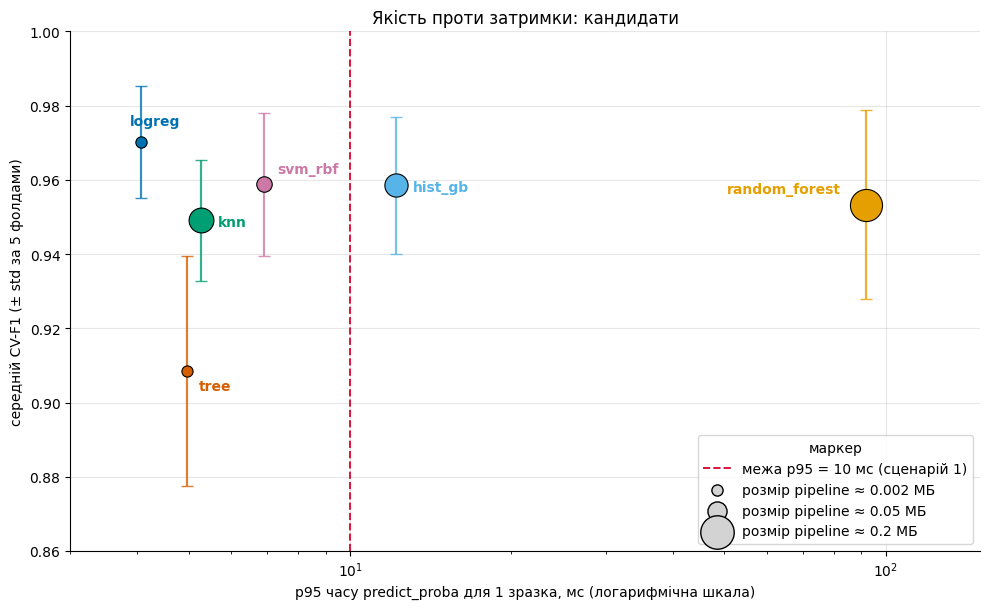

In [11]:
OFFS = {"logreg": (-8, 12), "tree": (8, -14), "knn": (12, -4), "svm_rbf": (10, 8),
        "random_forest": (-100, 8), "hist_gb": (12, -4)}
fig, ax = plt.subplots(figsize=(10, 6.2))
for m in ORDER:
    r = res.loc[m]
    ax.errorbar(r["latency_p95_ms_b1"], r["cv_f1_mean"], yerr=r["cv_f1_std"], fmt="none",
                ecolor=MC[m], elinewidth=1.6, capsize=4, alpha=0.8, zorder=2)
    ax.scatter(r["latency_p95_ms_b1"], r["cv_f1_mean"], s=60 + 2600 * r["model_size_mb"], color=MC[m],
               edgecolor="black", linewidth=0.8, zorder=3)
    ax.annotate(m, (r["latency_p95_ms_b1"], r["cv_f1_mean"]), textcoords="offset points", xytext=OFFS[m],
                fontsize=10, color=MC[m], fontweight="bold")
ax.axvline(10.0, color="crimson", ls="--", lw=1.4, label="межа p95 = 10 мс (сценарій 1)")
for mb in (0.002, 0.05, 0.2):
    ax.scatter([], [], s=60 + 2600 * mb, color="lightgrey", edgecolor="black", label=f"розмір pipeline ≈ {mb} МБ")
ax.set_xscale("log")
ax.set_xlim(3, 150)
ax.set_ylim(0.86, 1.0)
ax.set_xlabel("p95 часу predict_proba для 1 зразка, мс (логарифмічна шкала)")
ax.set_ylabel("середній CV-F1 (± std за 5 фолдами)")
ax.set_title("Якість проти затримки: кандидати")
ax.legend(loc="lower right", title="маркер")
fig.tight_layout()
save_show(fig, "01_quality_vs_latency.png")

**Інтерпретація рис. 1.** Найкраща точка — `logreg`: найвищий середній $F_1=0{,}970$ (± 0,015) і одночасно найменший $p95=4{,}07$ мс серед моделей, чий $F_1$ вищий за 0,95; розмір 2,4 КБ (найменший маркер).
Права межа сценарію 1 (10 мс) відсікає двох: `hist_gb` ($p95=12{,}19$ мс) і `random_forest` ($p95=91{,}94$ мс, у 22,6 раза повільніша за `logreg`). `svm_rbf` ($6{,}89$ мс, $F_1=0{,}959$) і `knn` ($5{,}26$ мс, $F_1=0{,}949$) лишаються ліворуч від межі.
Складніші ансамблі **не купують якості**: `random_forest` і `hist_gb` мають $F_1=0{,}953$ і $0{,}959$ — не вище за `svm_rbf` і нижче за `logreg`, а платять 3–22-кратним зростанням затримки.
Найгірша за якістю — `tree` ($F_1=0{,}908$ ± 0,031); лише її інтервал (верхня межа $0{,}9085+0{,}0311\approx0{,}940$) цілком лежить нижче нижньої межі інтервалу `logreg` ($0{,}9703-0{,}0151\approx0{,}955$). Інтервали решти п'яти моделей перекриваються (докладніше — у кінці розділу).
Вісь $x$ логарифмічна: різниця між 4 і 7 мс виглядає скромною, хоча це 1,7 раза.

### Рис. 2. Розподіл повторних вимірювань затримки

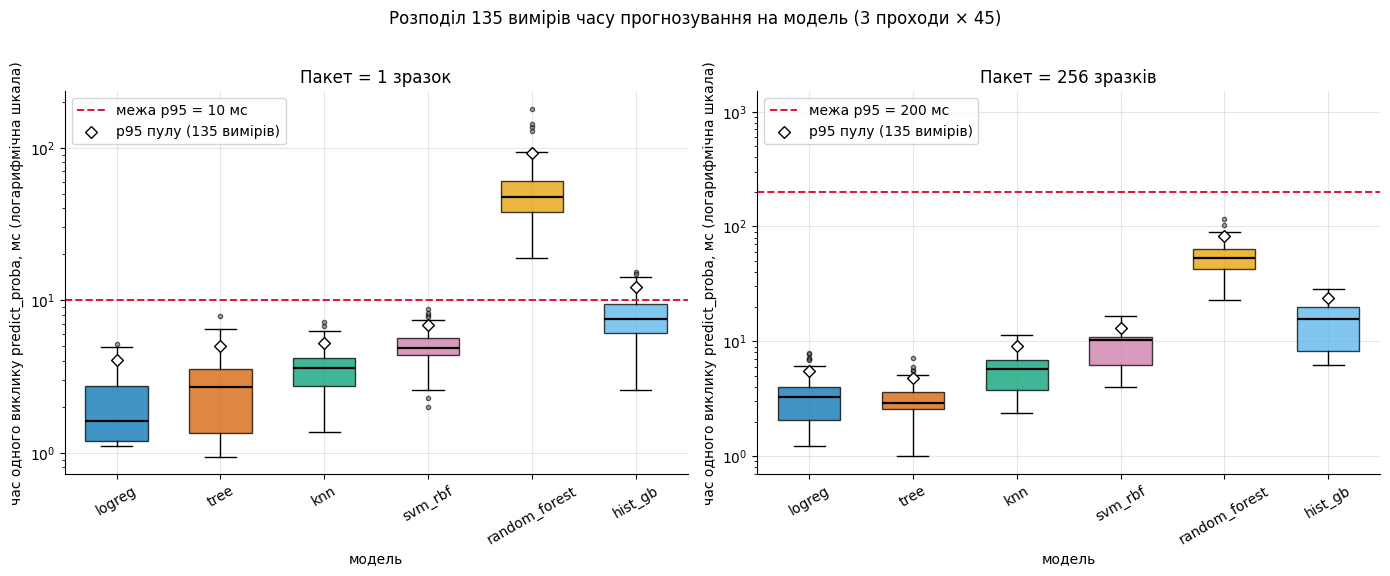

min     p50     p95      max  p95/p50  мс на зразок (p50/batch)
batch модель                                                                           
1     logreg          1.099   1.616   4.068    5.173    2.518                     1.616
      tree            0.942   2.697   4.968    7.908    1.842                     2.697
      knn             1.355   3.604   5.261    7.142    1.460                     3.604
      svm_rbf         1.986   4.820   6.890    8.702    1.429                     4.820
      random_forest  18.908  47.368  91.940  180.166    1.941                    47.368
      hist_gb         2.572   7.502  12.186   15.235    1.624                     7.502
256   logreg          1.234   3.264   5.521    7.910    1.691                     0.013
      tree            1.009   2.898   4.765    7.162    1.644                     0.011
      knn             2.372   5.750   9.011   11.376    1.567                     0.022
      svm_rbf         4.015  10.161  13.145   16.726    1.294                     0.040
      random_forest  22.700  53.224  82.665  115.293    1.553                     0.208
      hist_gb         6.196  15.583  23.942   28.488    1.536                     0.061

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
for ax, bs, lim, title in zip(axes, (1, 256), (10.0, 200.0), ("Пакет = 1 зразок", "Пакет = 256 зразків")):
    series = [samples[(samples["model"] == m) & (samples["batch_size"] == bs)]["ms"].to_numpy() for m in ORDER]
    bp = ax.boxplot(series, tick_labels=ORDER, patch_artist=True, widths=0.6,
                    medianprops={"color": "black", "linewidth": 1.6},
                    flierprops={"marker": "o", "markersize": 3, "markerfacecolor": "grey", "alpha": 0.6})
    for patch, m in zip(bp["boxes"], ORDER):
        patch.set_facecolor(MC[m])
        patch.set_alpha(0.75)
    ax.axhline(lim, color="crimson", ls="--", lw=1.4, label=f"межа p95 = {lim:g} мс")
    p95 = [np.percentile(s, 95) for s in series]
    ax.scatter(range(1, 7), p95, marker="D", color="white", edgecolor="black", zorder=4, label="p95 пулу (135 вимірів)")
    ax.set_yscale("log")
    ax.set_xlabel("модель")
    ax.set_ylabel("час одного виклику predict_proba, мс (логарифмічна шкала)")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=30)
    if bs == 256:
        ax.set_ylim(0.7, 1500)
    ax.legend(loc="upper left")
fig.suptitle("Розподіл 135 вимірів часу прогнозування на модель (3 проходи × 45)", y=1.02)
fig.tight_layout()
save_show(fig, "02_latency_distributions.png")

stat_rows = []
for bs in (1, 256):
    for m in ORDER:
        v = samples[(samples["model"] == m) & (samples["batch_size"] == bs)]["ms"].to_numpy()
        stat_rows.append({"batch": bs, "модель": m, "min": v.min(), "p50": np.percentile(v, 50), "p95": np.percentile(v, 95),
                          "max": v.max(), "p95/p50": np.percentile(v, 95) / np.percentile(v, 50),
                          "мс на зразок (p50/batch)": np.percentile(v, 50) / bs})
display(pd.DataFrame(stat_rows).set_index(["batch", "модель"]).round(3))

**Інтерпретація рис. 2.** Для пакета з одного зразка медіани $p50$: `logreg` 1,62 мс, `tree` 2,70, `knn` 3,60, `svm_rbf` 4,82, `hist_gb` 7,50, `random_forest` 47,37 мс. Уся коробка `random_forest` лежить вище межі 10 мс (мінімум серед 135 вимірів — 18,9 мс, максимум — 180 мс); `hist_gb` перетинає межу лише хвостом ($p95=12{,}19$ мс).
У `logreg` найважчий хвіст: $p95/p50=2{,}52$ (при 1,4–1,9 в інших моделей) — на мілісекундних масштабах одиничні збої планувальника вже помітні.
Для пакета 256 усі моделі далеко від межі 200 мс (найгірша — `random_forest`, $p95=82{,}7$ мс): **обмеження на затримку пакета в сценарії 2 нікого не відсікає**. Пакет у 256 разів більший коштує лише ~2 рази довше для `logreg` (3,26 мс проти 1,62 мс), тобто на 1 зразок виходить 0,013 мс проти 1,62 мс: у режимі «один зразок» домінують сталі накладні витрати виклику `Pipeline`.
Саме тому для критерію затримки в сценарії 1 орієнтир `best` = 1 мс (порядок цих накладних витрат). Пропускна здатність (зразків/с) тут — похідна від $p50$ на пакеті 256: від 4 810 (`random_forest`) до 88 322 (`tree`); `logreg` — 78 427.

### Рис. 3. Шум вимірювання: p95 по проходах

Кожен прохід — окремий вимір p95 на 45 викликів. Розкид між проходами показує, наскільки *одиничний* запуск ненадійний для p95.

,pass1,pass2,pass3,pooled_p95,min_pass,max_pass,max/min,проходів з p95 > 10 мс
model,,,,,,,,
logreg,2.805,4.560,2.129,4.068,2.129,4.560,2.142,0
tree,3.132,6.251,3.705,4.968,3.132,6.251,1.996,0
knn,4.533,5.791,4.352,5.261,4.352,5.791,1.331,0
svm_rbf,7.605,7.013,6.064,6.890,6.064,7.605,1.254,0
random_forest,69.716,89.195,135.858,91.940,69.716,135.858,1.949,3
hist_gb,13.957,8.045,11.569,12.186,8.045,13.957,1.735,2


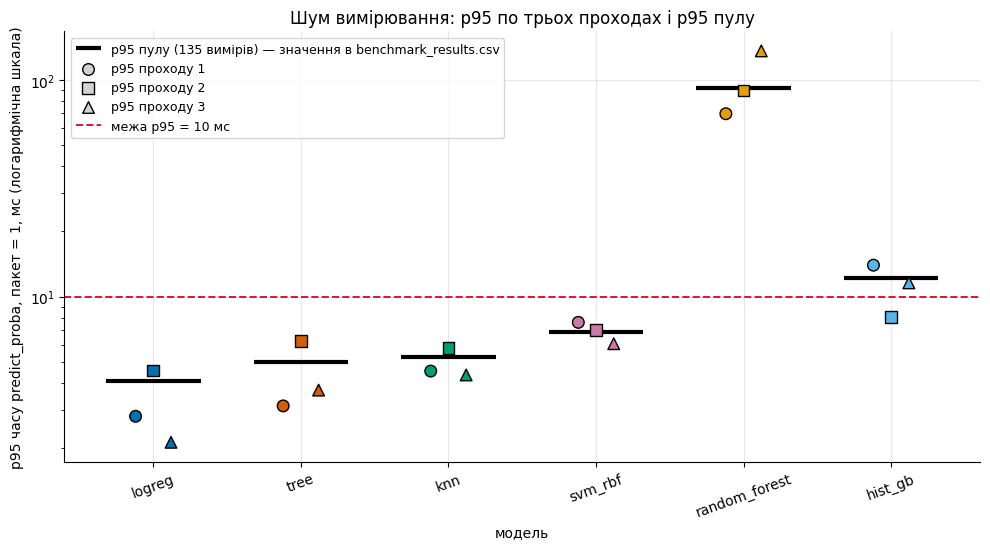

In [13]:
passes = res[[f"latency_p95_ms_b1_pass{p}" for p in (1, 2, 3)]].copy()
passes.columns = ["pass1", "pass2", "pass3"]
passes["pooled_p95"] = res["latency_p95_ms_b1"]
passes["min_pass"] = passes[["pass1", "pass2", "pass3"]].min(axis=1)
passes["max_pass"] = passes[["pass1", "pass2", "pass3"]].max(axis=1)
passes["max/min"] = passes["max_pass"] / passes["min_pass"]
passes["проходів з p95 > 10 мс"] = (passes[["pass1", "pass2", "pass3"]] > 10.0).sum(axis=1)
display(passes.round(3))

fig, ax = plt.subplots(figsize=(10, 5.6))
x = np.arange(len(ORDER))
ax.hlines(passes["pooled_p95"], x - 0.32, x + 0.32, color="black", lw=3, label="p95 пулу (135 вимірів) — значення в benchmark_results.csv", zorder=2)
for p, mk in zip((1, 2, 3), ("o", "s", "^")):
    ax.scatter(x + (p - 2) * 0.12, passes[f"pass{p}"], marker=mk, s=70, color=[MC[m] for m in ORDER],
               edgecolor="black", zorder=3)
    ax.scatter([], [], marker=mk, s=70, color="lightgrey", edgecolor="black", label=f"p95 проходу {p}")
ax.axhline(10.0, color="crimson", ls="--", lw=1.4, label="межа p95 = 10 мс")
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(ORDER, rotation=20)
ax.set_xlabel("модель")
ax.set_ylabel("p95 часу predict_proba, пакет = 1, мс (логарифмічна шкала)")
ax.set_title("Шум вимірювання: p95 по трьох проходах і p95 пулу")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
save_show(fig, "03_latency_per_pass.png")

**Інтерпретація рис. 3.** $p95$ одного проходу (45 вимірів) сильно шумить: відношення «максимум/мінімум» між трьома проходами — від 1,25 (`svm_rbf`: 6,06–7,60 мс) до 2,14 (`logreg`: 2,13–4,56 мс); для `hist_gb` проходи дали 13,96 / 8,05 / 11,57 мс (×1,74), а пул із 135 вимірів — 12,19 мс.
Для `hist_gb` це критично: два проходи з трьох порушують межу 10 мс, а один — ні. Якби вимір був одиничним, вердикт «швидкість неприйнятна» залежав би від випадку: у попередніх одиничних запусках (історія комітів) для тієї самої моделі виходило 10,53 і 8,88 мс —
разом п'ять одиничних значень у діапазоні 8,05–13,96 мс, три з яких вище за межу, а два нижче. Звідси протокол «3 проходи, моделі по черзі, p95 на пулі» (менший шум, дрейф однаково впливає на всіх), але й він залишається виміром **на одній машині**.
Решта моделей далека від межі в кожному проході: `logreg` ≤ 4,56 мс, `svm_rbf` ≤ 7,61 мс, `random_forest` ≥ 69,7 мс — тож обмеження на затримку для них не залежить від шуму. Відповідний аналіз вердикту «по проходах» — одразу після рис. 6.

### Рис. 4. Розмір серіалізованого pipeline

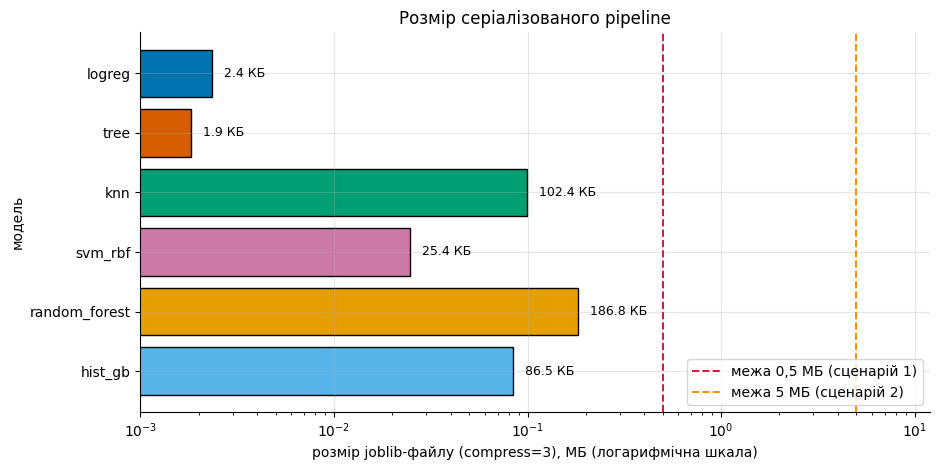

In [14]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
size = res["model_size_mb"]
bars = ax.barh(ORDER, size, color=[MC[m] for m in ORDER], edgecolor="black")
for m, v in zip(ORDER, size):
    ax.text(v * 1.15, m, f"{v * 1024:.1f} КБ", va="center", fontsize=9)
ax.axvline(0.5, color="crimson", ls="--", lw=1.4, label="межа 0,5 МБ (сценарій 1)")
ax.axvline(5.0, color="darkorange", ls="--", lw=1.4, label="межа 5 МБ (сценарій 2)")
ax.set_xscale("log")
ax.set_xlim(1e-3, 12)
ax.invert_yaxis()
ax.set_xlabel("розмір joblib-файлу (compress=3), МБ (логарифмічна шкала)")
ax.set_ylabel("модель")
ax.set_title("Розмір серіалізованого pipeline")
ax.legend(loc="lower right")
fig.tight_layout()
save_show(fig, "04_model_size.png")

**Інтерпретація рис. 4.** Усі шість pipeline дуже малі: від 1,9 КБ (`tree`) та 2,4 КБ (`logreg`: 30 коефіцієнтів + параметри скейлера й імпутера) до 186,8 КБ (`random_forest`, 300 дерев); `knn` займає 102 КБ, бо зберігає навчальні дані, `hist_gb` — 86,5 КБ, `svm_rbf` — 25,4 КБ.
Найбільший файл (0,182 МБ) становить 36 % межі 0,5 МБ сценарію 1 і менш ніж 4 % межі 5 МБ сценарію 2: **обмеження на розмір не відсікає жодного кандидата в жодному сценарії**. Це чесний результат: для tabular-моделей на 569 зразках розмір не є вузьким місцем,
а критерій `model_size_mb` (вага 0,10 у сценарії 1) майже не розрізняє моделі: $z=0{,}995$ у `logreg` і $0{,}950$ у `svm_rbf` — внесок у різницю балів лише 0,0045.

### Рис. 5. Результати по фолдах

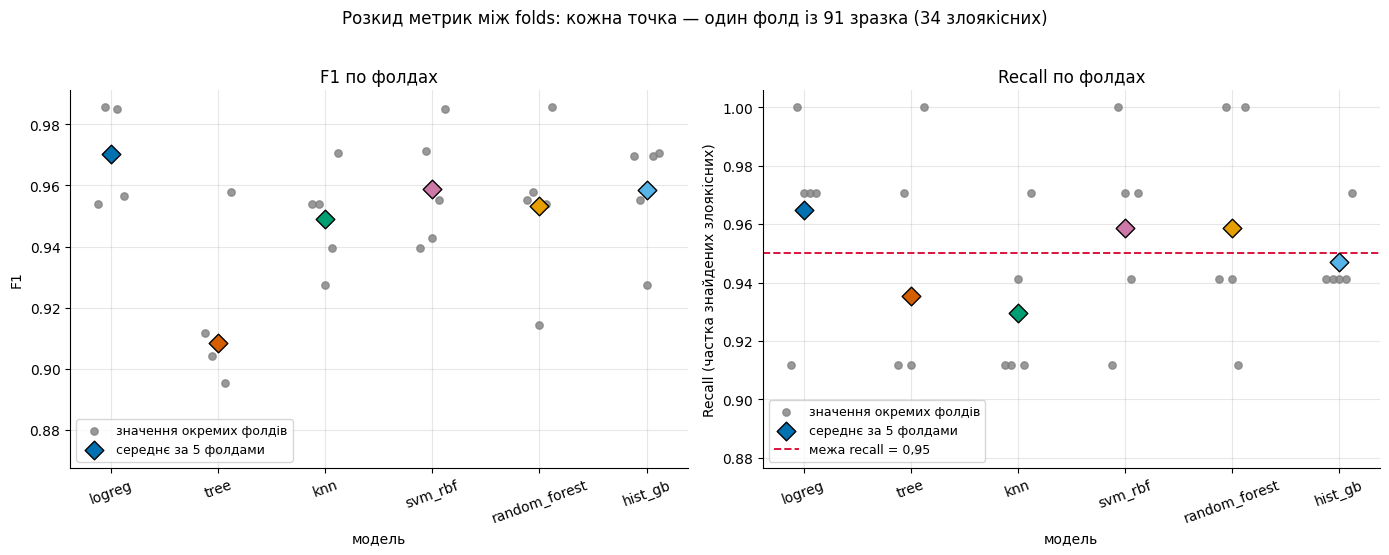

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
rng = np.random.default_rng(0)
for ax, metric, title in zip(axes, ("f1", "recall"), ("F1 по фолдах", "Recall по фолдах")):
    for i, m in enumerate(ORDER):
        vals = fold_df[fold_df["model"] == m].sort_values("fold")[metric].to_numpy()
        ax.scatter(i + (np.arange(5) - 2) * 0.06, vals, color="grey", s=28, alpha=0.8, zorder=2,
                   label="значення окремих фолдів" if i == 0 else None)
        ax.scatter(i, vals.mean(), marker="D", s=90, color=MC[m], edgecolor="black", zorder=3,
                   label="середнє за 5 фолдами" if i == 0 else None)
    if metric == "recall":
        ax.axhline(0.95, color="crimson", ls="--", lw=1.4, label="межа recall = 0,95")
    ax.set_xticks(range(6))
    ax.set_xticklabels(ORDER, rotation=20)
    ax.set_xlabel("модель")
    ax.set_ylabel(metric.upper() if metric == "f1" else "Recall (частка знайдених злоякісних)")
    ax.set_title(title)
    ax.legend(loc="lower left", fontsize=9)
fig.suptitle("Розкид метрик між folds: кожна точка — один фолд із 91 зразка (34 злоякісних)", y=1.02)
fig.tight_layout()
save_show(fig, "05_fold_scores.png")

**Інтерпретація рис. 5.** Кожен фолд — лише 91 зразок із 34 злоякісними, тому recall фолду приймає дискретні значення $k/34$: 0,912 (3 FN), 0,941 (2 FN), 0,971 (1 FN), 1,0; один FN — це 2,9 п. п. recall фолду.
Межа 0,95 стосується **середнього** recall, а не кожного фолду: навіть у `logreg` один фолд (№ 1, 3 пропущені) має recall 0,912. Фолд № 1 — найважчий майже для всіх моделей (3 FN у `logreg`, `tree`, `knn`, `svm_rbf`; 2 FN у `random_forest` і `hist_gb`), що вказує на кілька складних злоякісних випадків, спільних для різних алгоритмів.
Розкид $F_1$ між фолдами значний: у `logreg` від 0,954 до 0,986, у `random_forest` від 0,914 до 0,986, у `tree` від 0,873 до 0,958. Точка `hist_gb` на рис. 5 (recall) лежить нижче лінії 0,95 лише на 0,003 — це 9 пропущених із 170 проти допустимих 8,5.

In [16]:
# чи відрізняються моделі за F1 на фоні розкиду між фолдами? Парні різниці на тих самих фолдах (logreg - інша)
piv = fold_df.pivot(index="fold", columns="model", values="f1")[ORDER]
rows = []
for m in ORDER[1:]:
    d = piv["logreg"] - piv[m]
    rows.append({"logreg мінус": m, "середня різниця F1": d.mean(), "std різниці": d.std(ddof=1),
                 "фолдів, де logreg кращий (з 5)": int((d > 0).sum()),
                 "середня різниця / (std/√5)": d.mean() / (d.std(ddof=1) / np.sqrt(5))})
paired = pd.DataFrame(rows).set_index("logreg мінус")
display(paired.round(4))
se = res["cv_f1_std"] / np.sqrt(5)
print("Стандартна похибка середнього F1 (std/√5):", se.round(4).to_dict())
print("Розрив між 2-м і 5-м місцем за середнім F1:",
      round(res["cv_f1_mean"].sort_values(ascending=False).iloc[1] - res["cv_f1_mean"].sort_values(ascending=False).iloc[4], 4))

,середня різниця F1,std різниці,"фолдів, де logreg кращий (з 5)",середня різниця / (std/√5)
logreg мінус,,,,
tree,0.0618,0.0412,4,3.3585
knn,0.0213,0.0268,3,1.7723
svm_rbf,0.0115,0.0236,4,1.0927
random_forest,0.0170,0.0328,3,1.1564
hist_gb,0.0118,0.0263,3,1.0001


Стандартна похибка середнього F1 (std/√5): {'logreg': 0.0067, 'tree': 0.0139, 'knn': 0.0073, 'svm_rbf': 0.0086, 'random_forest': 0.0114, 'hist_gb': 0.0083}
Розрив між 2-м і 5-м місцем за середнім F1: 0.0098


**Різниця якості на тлі розкиду.** Стандартна похибка середнього $F_1$ за 5 фолдами (std/$\sqrt5$) — від 0,007 (`logreg`) до 0,014 (`tree`), тобто того ж порядку, що й різниці між моделями: середній $F_1$ другого–п'ятого місць (`svm_rbf` 0,9588, `hist_gb` 0,9585, `random_forest` 0,9533, `knn` 0,9490) укладається в 0,0098.
Парні різниці на тих самих фолдах (таблиця вище): `logreg` кращий за `svm_rbf` на 0,0115 (std різниці 0,0236; кращий у 4 з 5 фолдів), за `hist_gb` на 0,0118 (3 з 5), за `random_forest` на 0,0170 (3 з 5), за `knn` на 0,0213 (3 з 5). Відношення «середня різниця / (std/$\sqrt5$)» дорівнює 1,09; 1,00; 1,16; 1,77 — усі нижче
критичного $t\approx2{,}78$ для 4 ступенів свободи; лише `tree` (3,36) явно гірша. До того ж фолди CV не незалежні (навчальні частини перекриваються), тож навіть ці відношення оптимістичні.
**Висновок для вибору:** за якістю `logreg`, `svm_rbf`, `hist_gb`, `random_forest` і `knn` статистично **не розрізняються**; перевага `logreg` в $F_1$ — це напрям, а не доведений факт. Тому рішення справедливо спирається на жорсткі обмеження й інженерні критерії (затримка, розмір, стабільність), де відмінності великі й відтворювані, а не на третій знак $F_1$.

## 5. Сценарій 1: `realtime_workstation` (завдання 6–10)

Конфігурація — окремий JSON (`configs/realtime_workstation.json`); Python-код про сценарій нічого не знає. `load_config` перевіряє структуру й суму ваг (= 1).
Орієнтири нормалізації (`worst`/`best`) мають названі джерела (`anchor_sources`). **Орієнтири — фіксовані й не залежать від набору кандидатів** (чому — розділ 10).

In [17]:
cfg1 = load_config(ROOT / "configs" / "realtime_workstation.json")
cfg2 = load_config(ROOT / "configs" / "batch_second_reading.json")


def show_config(cfg):
    print(f"Сценарій: {cfg['scenario']} | версія {cfg['version']} | batch_size = {cfg.get('batch_size')}")
    print(cfg["description"], "\n")
    cons = pd.DataFrame([{"метрика": k, "min": v.get("min"), "max": v.get("max")} for k, v in cfg["constraints"].items()])
    print("Жорсткі обмеження (межі включні):")
    display(cons.set_index("метрика"))
    crit = pd.DataFrame(cfg["criteria"]).T
    crit["джерело орієнтирів"] = pd.Series(cfg["anchor_sources"])
    print("Критерії (ваги сумуються до 1: сума =", round(crit["weight"].astype(float).sum(), 12), "):")
    display(crit)


show_config(cfg1)

Сценарій: realtime_workstation | версія 1.0.0 | batch_size = 1
Синхронна підказка на робочій станції цитолога: прогноз для одного зразка одразу після сегментації ядер; спільний CPU, 1 потік; модель постачається в пакеті оновлення ПЗ станції. 

Жорсткі обмеження (межі включні):


,min,max
метрика,,
cv_recall_mean,0.95,NaN
latency_p95_ms_b1,NaN,10.0
model_size_mb,NaN,0.5


Критерії (ваги сумуються до 1: сума = 1.0 ):


,direction,weight,worst,best,джерело орієнтирів
cv_f1_mean,maximize,0.3,0.9,1.0,worst 0.90 = рівень окремого дерева з ЛР № 4 (≈0.91): гірше за просте дерево немає сенсу; best 1.0 = теоретична межа.
cv_recall_mean,maximize,0.25,0.95,1.0,worst 0.95 = жорстка межа сценарію (збігається з обмеженням на recall); best 1.0 = теоретична межа.
latency_p95_ms_b1,minimize,0.25,10.0,1.0,"worst 10 мс = межа обмеження на p95 для одного зразка; best 1 мс = порядок накладних витрат одного виклику sklearn Pipeline, швидше практично недосяжно."
model_size_mb,minimize,0.1,0.5,0.0,worst 0.5 МБ = межа обмеження на розмір пакета оновлення; best 0 = порожній файл.
cv_f1_std,minimize,0.1,0.05,0.0,worst 0.05 = типовий розкид F1 між folds у ЛР № 4 (≈0.03) із запасом; best 0 = повна стабільність.


In [18]:
ranking1, rejected1 = rank_models(results, cfg1)
print("Допущені моделі (рейтинг):")
display(ranking1.round(4))
print("Відхилені моделі та ВСІ порушення:")
display(rejected1)

Допущені моделі (рейтинг):


,rank,model,score,cv_f1_mean,cv_recall_mean,latency_p95_ms_b1,model_size_mb,cv_f1_std,z_cv_f1_mean,z_cv_recall_mean,z_latency_p95_ms_b1,z_model_size_mb,z_cv_f1_std
0,1,logreg,0.6186,0.9703,0.9647,4.0682,0.0023,0.0151,0.7031,0.2941,0.6591,0.9953,0.6983
1,2,svm_rbf,0.4633,0.9588,0.9588,6.8897,0.0248,0.0193,0.5880,0.1765,0.3456,0.9504,0.6136


Відхилені моделі та ВСІ порушення:


,model,violations,n_violations
0,hist_gb,cv_recall_mean=0.9471 < min 0.95; latency_p95_ms_b1=12.19 > max 10.0,2
1,knn,cv_recall_mean=0.9294 < min 0.95,1
2,random_forest,latency_p95_ms_b1=91.94 > max 10.0,1
3,tree,cv_recall_mean=0.9353 < min 0.95,1


In [19]:
# --- збереження вибору: результат має бути ідентичний закоміченим файлам -------------------------------
def snapshot(scenario):
    names = [f"ranking_{scenario}.csv", f"rejected_{scenario}.csv", f"selection_{scenario}.json",
             f"MODEL_SELECTION_{scenario}.md", f"selected_{scenario}.joblib", f"backup_{scenario}.joblib"]
    return {n: (RES / n).read_bytes() for n in names}


def save_and_check(ranking, rejected, cfg):
    sc = cfg["scenario"]
    before = snapshot(sc)
    committed_rank = pd.read_csv(RES / f"ranking_{sc}.csv")
    committed_rej = pd.read_csv(RES / f"rejected_{sc}.csv")
    # 1) таблиці, обчислені зараз, збігаються із закоміченими (до перезапису)
    pd.testing.assert_frame_equal(ranking.reset_index(drop=True), committed_rank, check_exact=False, rtol=1e-12)
    pd.testing.assert_frame_equal(rejected.reset_index(drop=True), committed_rej, check_exact=False)
    # 2) запис тією ж функцією, що в select_model.py
    sel = save_selection(ranking, rejected, cfg, RES, RES / "models", config_path=f"configs/{sc}.json")
    after = snapshot(sc)
    same_bytes = {n: before[n] == after[n] for n in before}
    return sel, same_bytes


sel1, same1 = save_and_check(ranking1, rejected1, cfg1)
print("Файли сценарію 1 побайтно збігаються з закоміченими:", same1)
print(json.dumps(sel1, ensure_ascii=False, indent=2))

Файли сценарію 1 побайтно збігаються з закоміченими:

 {'ranking_realtime_workstation.csv': True, 'rejected_realtime_workstation.csv': True, 'selection_realtime_workstation.json': True, 'MODEL_SELECTION_realtime_workstation.md': True, 'selected_realtime_workstation.joblib': True, 'backup_realtime_workstation.joblib': True}
{
  "scenario": "realtime_workstation",
  "config_version": "1.0.0",
  "config_path": "configs/realtime_workstation.json",
  "primary": {
    "model": "logreg",
    "score": 0.6185877501003367,
    "file": "selected_realtime_workstation.joblib"
  },
  "backup": {
    "model": "svm_rbf",
    "score": 0.4632957945732641,
    "file": "backup_realtime_workstation.joblib"
  },
  "score_gap": 0.15529195552707264,
  "rejected": [
    {
      "model": "hist_gb",
      "reasons": [
        "cv_recall_mean=0.9471 < min 0.95",
        "latency_p95_ms_b1=12.19 > max 10.0"
      ]
    },
    {
      "model": "knn",
      "reasons": [
        "cv_recall_mean=0.9294 < min 0.95"
      ]
    },
    {
      "model": "random_forest",
    

In [20]:
# --- ручний перерахунок балу переможця з z-значень і ваг -----------------------------------------------
win = ranking1.iloc[0]
manual = 0.0
rows = []
for name, spec in cfg1["criteria"].items():
    z = normalize_value(win[name], spec)                    # z вручну з сирого значення
    assert np.isclose(z, win[f"z_{name}"])
    rows.append({"критерій": name, "значення": win[name], "напрям": spec["direction"],
                 "worst": spec["worst"], "best": spec["best"], "z": z, "вага": spec["weight"], "внесок w*z": spec["weight"] * z})
    manual += spec["weight"] * z
detail = pd.DataFrame(rows).set_index("критерій")
display(detail.round(4))
print(f"Σ w*z = {manual:.10f} | score з rank_models = {win['score']:.10f}")
assert np.isclose(manual, win["score"], atol=1e-12)

# і одна z вручну 'на папері': F1 logreg
f1v = win["cv_f1_mean"]
print(f"\nПриклад: z_cv_f1_mean = ({f1v:.4f} - 0.90) / (1.00 - 0.90) = {(f1v - 0.90) / 0.10:.4f}")

,значення,напрям,worst,best,z,вага,внесок w*z
критерій,,,,,,,
cv_f1_mean,0.9703,maximize,0.90,1.0,0.7031,0.30,0.2109
cv_recall_mean,0.9647,maximize,0.95,1.0,0.2941,0.25,0.0735
latency_p95_ms_b1,4.0682,minimize,10.00,1.0,0.6591,0.25,0.1648
model_size_mb,0.0023,minimize,0.50,0.0,0.9953,0.10,0.0995
cv_f1_std,0.0151,minimize,0.05,0.0,0.6983,0.10,0.0698


Σ w*z = 0.6185877501 | score з rank_models = 0.6185877501

Приклад: z_cv_f1_mean = (0.9703 - 0.90) / (1.00 - 0.90) = 0.7031


### Рис. 6. Внесок критеріїв у бал (сценарій 1)

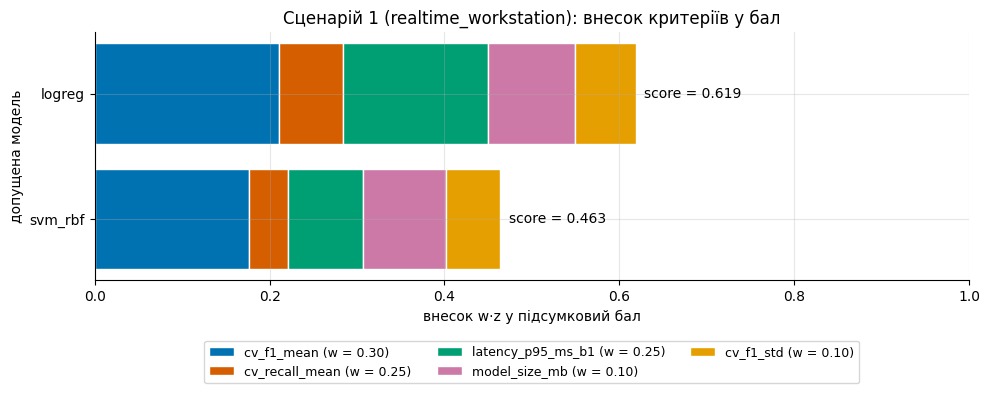

In [21]:
CRIT_COLORS = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00"]


def stacked_contrib(ax, ranking, cfg, title):
    crit = list(cfg["criteria"])
    left = np.zeros(len(ranking))
    labels = ranking["model"].tolist()
    for c, col in zip(crit, CRIT_COLORS):
        w = cfg["criteria"][c]["weight"]
        contrib = w * ranking[f"z_{c}"].to_numpy()
        ax.barh(labels, contrib, left=left, color=col, edgecolor="white", label=f"{c} (w = {w:.2f})")
        left += contrib
    for i, s in enumerate(ranking["score"]):
        ax.text(s + 0.01, i, f"score = {s:.3f}", va="center", fontsize=10)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.0)
    ax.set_xlabel("внесок w·z у підсумковий бал")
    ax.set_ylabel("допущена модель")
    ax.set_title(title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=9)


fig, ax = plt.subplots(figsize=(10, 4.2))
stacked_contrib(ax, ranking1, cfg1, "Сценарій 1 (realtime_workstation): внесок критеріїв у бал")
fig.tight_layout()
save_show(fig, "06_normalized_criteria_realtime.png")

**Інтерпретація рис. 6.** Бал `logreg` = 0,6186, `svm_rbf` = 0,4633; відрив 0,1553. Внесок критеріїв у відрив: затримка $0{,}25\cdot(0{,}659-0{,}346)=0{,}0784$ (50,5 %), $F_1$ 0,0345 (22,2 %), recall 0,0294 (18,9 %), стабільність $F_1$ 0,0085 (5,5 %), розмір 0,0045 (2,9 %); переможець кращий за **кожним** критерієм.
Затримка — головний чинник різниці, хоча її вага (0,25) менша за вагу $F_1$ (0,30): вона розрізняє моделі найсильніше (на шкалі 1–10 мс `logreg` має $z=0{,}659$, `svm_rbf` — 0,346). Критерій recall отримав «низькі» $z$ (0,294 і 0,176) через
орієнтир $\text{worst}=0{,}95$, що збігається з обмеженням: допущена модель із recall 0,965 на шкалі [0,95; 1] має лише 30 % балу. Розмір дає всім майже повний бал (>0,95) і практично не впливає на результат.

In [22]:
# --- стійкість рішення до шуму часу: той самий відбір, але з p95 кожного окремого проходу -----------------
rows = []
for p in (1, 2, 3):
    r = results.copy()
    r["latency_p95_ms_b1"] = r[f"latency_p95_ms_b1_pass{p}"]
    rk, rj = rank_models(r, cfg1)
    hist_viol = rj.set_index("model").loc["hist_gb", "violations"]
    rows.append({"джерело p95": f"прохід {p}", "переможець": rk.loc[0, "model"], "резервна": rk.loc[1, "model"],
                 "відрив": rk.loc[0, "score"] - rk.loc[1, "score"], "допущені": ", ".join(rk["model"]),
                 "hist_gb p95, мс": r.set_index("model").loc["hist_gb", "latency_p95_ms_b1"],
                 "порушення hist_gb": hist_viol})
rk0, rj0 = rank_models(results, cfg1)
rows.insert(0, {"джерело p95": "пул (як у рейтингу)", "переможець": rk0.loc[0, "model"], "резервна": rk0.loc[1, "model"],
                "відрив": rk0.loc[0, "score"] - rk0.loc[1, "score"], "допущені": ", ".join(rk0["model"]),
                "hist_gb p95, мс": results.set_index("model").loc["hist_gb", "latency_p95_ms_b1"],
                "порушення hist_gb": rj0.set_index("model").loc["hist_gb", "violations"]})
display(pd.DataFrame(rows).set_index("джерело p95").round(4))

,переможець,резервна,відрив,допущені,"hist_gb p95, мс",порушення hist_gb
джерело p95,,,,,,
пул (як у рейтингу),logreg,svm_rbf,0.1553,"logreg, svm_rbf",12.1856,cv_recall_mean=0.9471 < min 0.95; latency_p95_ms_b1=12.19 > max 10.0
прохід 1,logreg,svm_rbf,0.2102,"logreg, svm_rbf",13.9574,cv_recall_mean=0.9471 < min 0.95; latency_p95_ms_b1=13.96 > max 10.0
прохід 2,logreg,svm_rbf,0.1450,"logreg, svm_rbf",8.0455,cv_recall_mean=0.9471 < min 0.95
прохід 3,logreg,svm_rbf,0.1862,"logreg, svm_rbf",11.5689,cv_recall_mean=0.9471 < min 0.95; latency_p95_ms_b1=11.57 > max 10.0


**Стійкість до шуму часу.** Якщо замість $p95$ пулу брати $p95$ окремого проходу, переможець і резервна не змінюються ні в одному з трьох проходів (`logreg` / `svm_rbf`; відрив 0,1450–0,2102 проти 0,1553 для пулу), допущена множина — теж `{logreg, svm_rbf}`.
`hist_gb` у кожному варіанті відхилена: у проходах 1 і 3 за двома причинами (recall та затримка 13,96 / 11,57 мс), у проході 2 (8,05 мс) — лише за recall 0,9471. Рішення не залежить від шумного виміру, бо recall — це CV-метрика, що від машини не залежить;
затримка `hist_gb` лише «додає аргументів» до відхилення. Це важливе проєктне зауваження: **жорстку відмову за нестабільною метрикою потрібно підкріплювати стабільною** (або вимірювати кілька разів, як тут).

## 6. Сценарій 2: `batch_second_reading` (завдання 11)

Альтернативна конфігурація **без зміни Python-коду**: нічне пакетне прочитання на сервері, пріоритет якості (ROC-AUC 0,45; $F_1$ 0,30; стабільність 0,15; час навчання 0,10),
затримка некритична (межа $p95\le200$ мс для пакета 256), розмір до 5 МБ. Recall ≥ 0,95 залишається жорсткою межею (ціна пропуску та сама), додано $F_1\ge0{,}94$.

In [23]:
show_config(cfg2)
ranking2, rejected2 = rank_models(results, cfg2)
print("\nДопущені моделі (рейтинг):")
display(ranking2.round(4))
print("Відхилені моделі та ВСІ порушення:")
display(rejected2)

Сценарій: batch_second_reading | версія 1.0.0 | batch_size = 256
Нічне пакетне повторне прочитання всіх зразків за день (пакети по 256) на сервері лабораторії; пріоритет якості, затримка некритична. 

Жорсткі обмеження (межі включні):


,min,max
метрика,,
cv_recall_mean,0.95,NaN
cv_f1_mean,0.94,NaN
latency_p95_ms_b256,NaN,200.0
model_size_mb,NaN,5.0


Критерії (ваги сумуються до 1: сума = 1.0 ):


,direction,weight,worst,best,джерело орієнтирів
cv_roc_auc_mean,maximize,0.45,0.95,1.0,worst 0.95 = нижня межа прийнятної якості ранжування для скринінгу; best 1.0 = теоретична межа.
cv_f1_mean,maximize,0.3,0.9,1.0,worst 0.90 = рівень окремого дерева з ЛР № 4 (≈0.91); best 1.0 = теоретична межа.
cv_f1_std,minimize,0.15,0.05,0.0,worst 0.05 = типовий розкид F1 між folds у ЛР № 4 (≈0.03) із запасом; best 0 = повна стабільність.
fit_time_s,minimize,0.1,10.0,0.0,worst 10 с = бюджет щомісячного перенавчання; best 0 = миттєве навчання.



Допущені моделі (рейтинг):


,rank,model,score,cv_roc_auc_mean,cv_f1_mean,cv_f1_std,fit_time_s,z_cv_roc_auc_mean,z_cv_f1_mean,z_cv_f1_std,z_fit_time_s
0,1,logreg,0.8284,0.9959,0.9703,0.0151,0.0130,0.9174,0.7031,0.6983,0.9987
1,2,svm_rbf,0.7776,0.9956,0.9588,0.0193,0.0848,0.9112,0.5880,0.6136,0.9915
2,3,random_forest,0.6832,0.9904,0.9533,0.0254,1.3735,0.8070,0.5332,0.4917,0.8626


Відхилені моделі та ВСІ порушення:


,model,violations,n_violations
0,hist_gb,cv_recall_mean=0.9471 < min 0.95,1
1,knn,cv_recall_mean=0.9294 < min 0.95,1
2,tree,cv_recall_mean=0.9353 < min 0.95; cv_f1_mean=0.9085 < min 0.94,2


In [24]:
sel2, same2 = save_and_check(ranking2, rejected2, cfg2)
print("Файли сценарію 2 побайтно збігаються з закоміченими:", same2)
print(json.dumps(sel2, ensure_ascii=False, indent=2))

win2 = ranking2.iloc[0]
manual2 = sum(spec["weight"] * normalize_value(win2[n], spec) for n, spec in cfg2["criteria"].items())
print(f"\nРучний перерахунок балу переможця: Σ w*z = {manual2:.10f} | score = {win2['score']:.10f}")
assert np.isclose(manual2, win2["score"], atol=1e-12)

Файли сценарію 2 побайтно збігаються з закоміченими: {'ranking_batch_second_reading.csv': True, 'rejected_batch_second_reading.csv': True, 'selection_batch_second_reading.json': True, 'MODEL_SELECTION_batch_second_reading.md': True, 'selected_batch_second_reading.joblib': True, 'backup_batch_second_reading.joblib': True}
{
  "scenario": "batch_second_reading",
  "config_version": "1.0.0",
  "config_path": "configs/batch_second_reading.json",
  "primary": {
    "model": "logreg",
    "score": 0.8283866754237564,
    "file": "selected_batch_second_reading.joblib"
  },
  "backup": {
    "model": "svm_rbf",
    "score": 0.7776341595334014,
    "file": "backup_batch_second_reading.joblib"
  },
  "score_gap": 0.05075251589035501,
  "rejected": [
    {
      "model": "hist_gb",
      "reasons": [
        "cv_recall_mean=0.9471 < min 0.95"
      ]
    },
    {
      "model": "knn",
      "reasons": [
        "cv_recall_mean=0.9294 < min 0.95"
      ]
    },
    {
      "model": "tree",
      "

### Рис. 7. Внесок критеріїв у бал (сценарій 2)

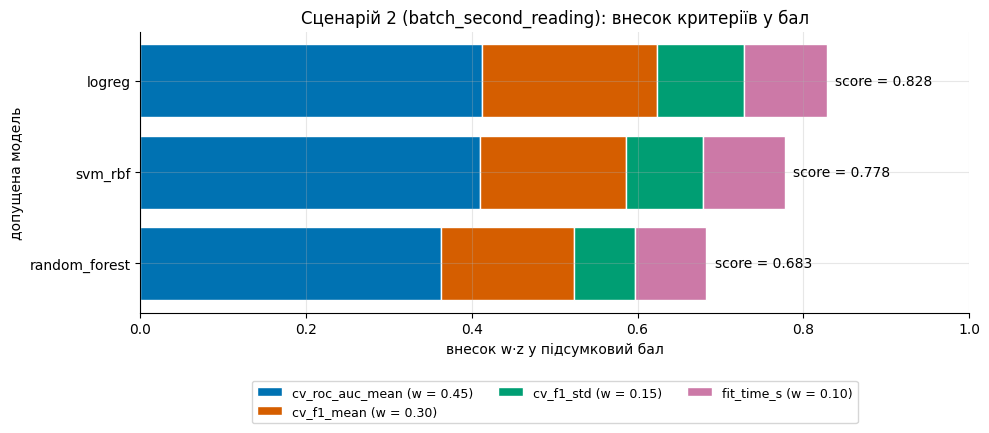

In [25]:
fig, ax = plt.subplots(figsize=(10, 4.6))
stacked_contrib(ax, ranking2, cfg2, "Сценарій 2 (batch_second_reading): внесок критеріїв у бал")
fig.tight_layout()
save_show(fig, "07_normalized_criteria_batch.png")

**Інтерпретація рис. 7.** Бали сценарію 2: `logreg` 0,8284, `svm_rbf` 0,7776, `random_forest` 0,6832; відрив 1-го від 2-го 0,0508, 2-го від 3-го 0,0944.
Найбільшу вагу має ROC-AUC (0,45), але він майже не розрізняє `logreg` і `svm_rbf` (0,9959 проти 0,9956; $z=0{,}917$ проти 0,911, внесок у відрив лише 0,0028, тобто 5,5 %): **вага критерію ≠ його вплив** — вплив залежить ще й від розкиду значень між кандидатами.
Основну частину відриву дає $F_1$ (0,0345; 68 %) і стабільність $F_1$ (0,0127; 25 %). Час навчання (вага 0,10) дає всім допущеним $z$ від 0,86 до 1,0 — майже без впливу, бо орієнтир 10 с значно перевищує реальні 0,013–1,37 с.

In [26]:
# --- порівняння двох сценаріїв -----------------------------------------------------------------------
def summary(rk, rj, cfg):
    return {"допущені": ", ".join(rk["model"]) + f" ({len(rk)})",
            "відхилені": "; ".join(f"{r.model} ({r.violations})" for r in rj.itertuples()),
            "переможець": f"{rk.loc[0, 'model']} ({rk.loc[0, 'score']:.4f})",
            "резервна": f"{rk.loc[1, 'model']} ({rk.loc[1, 'score']:.4f})",
            "відрив 1-го від 2-го": round(rk.loc[0, "score"] - rk.loc[1, "score"], 4),
            "критерії": ", ".join(f"{k} {v['weight']:.2f}" for k, v in cfg["criteria"].items())}


cmp = pd.DataFrame({"realtime_workstation": summary(ranking1, rejected1, cfg1),
                    "batch_second_reading": summary(ranking2, rejected2, cfg2)})
display(cmp)

# повна таблиця балів по обох сценаріях для всіх шести моделей
score_tbl = pd.DataFrame(index=ORDER)
score_tbl["realtime: score"] = ranking1.set_index("model")["score"].reindex(ORDER)
score_tbl["batch: score"] = ranking2.set_index("model")["score"].reindex(ORDER)
score_tbl["realtime: відхилення"] = rejected1.set_index("model")["violations"].reindex(ORDER).fillna("")
score_tbl["batch: відхилення"] = rejected2.set_index("model")["violations"].reindex(ORDER).fillna("")
display(score_tbl.round(4))

,realtime_workstation,batch_second_reading
допущені,"logreg, svm_rbf (2)","logreg, svm_rbf, random_forest (3)"
відхилені,hist_gb (cv_recall_mean=0.9471 < min 0.95; latency_p95_ms_b1=12.19 > max 10.0); knn (cv_recall_mean=0.9294 < min 0.95); random_forest (latency_p95_ms_b1=91.94 > max 10.0); tree (cv_recall_mean=0.9353 < min 0.95),hist_gb (cv_recall_mean=0.9471 < min 0.95); knn (cv_recall_mean=0.9294 < min 0.95); tree (cv_recall_mean=0.9353 < min 0.95; cv_f1_mean=0.9085 < min 0.94)
переможець,logreg (0.6186),logreg (0.8284)
резервна,svm_rbf (0.4633),svm_rbf (0.7776)
відрив 1-го від 2-го,0.1553,0.0508
критерії,"cv_f1_mean 0.30, cv_recall_mean 0.25, latency_p95_ms_b1 0.25, model_size_mb 0.10, cv_f1_std 0.10","cv_roc_auc_mean 0.45, cv_f1_mean 0.30, cv_f1_std 0.15, fit_time_s 0.10"


,realtime: score,batch: score,realtime: відхилення,batch: відхилення
logreg,0.6186,0.8284,,
tree,NaN,NaN,cv_recall_mean=0.9353 < min 0.95,cv_recall_mean=0.9353 < min 0.95; cv_f1_mean=0.9085 < min 0.94
knn,NaN,NaN,cv_recall_mean=0.9294 < min 0.95,cv_recall_mean=0.9294 < min 0.95
svm_rbf,0.4633,0.7776,,
random_forest,NaN,0.6832,latency_p95_ms_b1=91.94 > max 10.0,
hist_gb,NaN,NaN,cv_recall_mean=0.9471 < min 0.95; latency_p95_ms_b1=12.19 > max 10.0,cv_recall_mean=0.9471 < min 0.95


### Рис. 8. Бал моделей у двох сценаріях

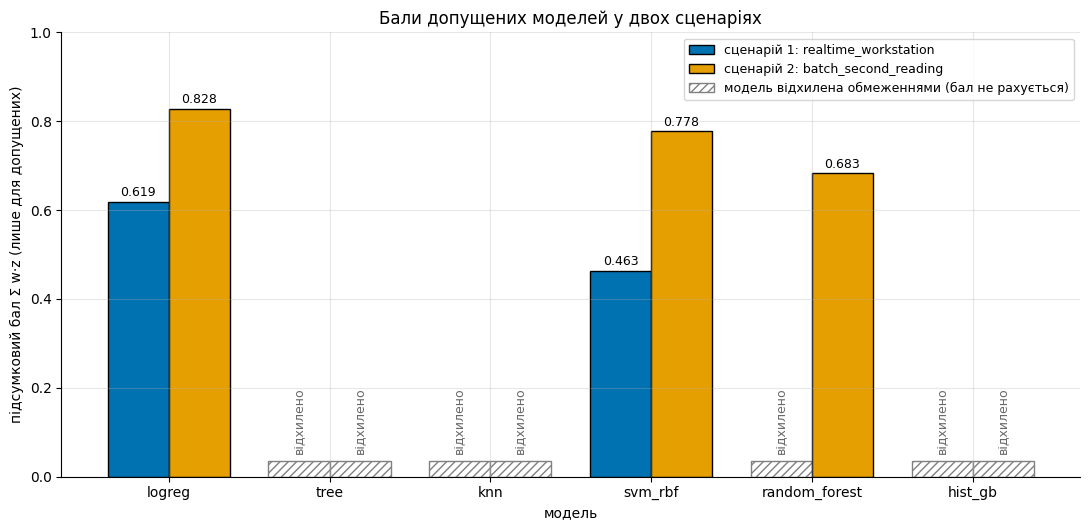

In [27]:
fig, ax = plt.subplots(figsize=(11, 5.4))
w = 0.38
x = np.arange(len(ORDER))
for off, rk, rj, lab, col in ((-w / 2, ranking1, rejected1, "сценарій 1: realtime_workstation", "#0072B2"),
                              (+w / 2, ranking2, rejected2, "сценарій 2: batch_second_reading", "#E69F00")):
    sc = rk.set_index("model")["score"]
    for i, m in enumerate(ORDER):
        if m in sc.index:
            ax.bar(i + off, sc[m], width=w, color=col, edgecolor="black")
            ax.text(i + off, sc[m] + 0.012, f"{sc[m]:.3f}", ha="center", fontsize=9)
        else:
            ax.bar(i + off, 0.035, width=w, color="white", edgecolor="grey", hatch="////")
            ax.text(i + off, 0.05, "відхилено", ha="center", va="bottom", rotation=90, fontsize=9, color="dimgrey")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor="#0072B2", edgecolor="black", label="сценарій 1: realtime_workstation"),
                   Patch(facecolor="#E69F00", edgecolor="black", label="сценарій 2: batch_second_reading"),
                   Patch(facecolor="white", edgecolor="grey", hatch="////", label="модель відхилена обмеженнями (бал не рахується)")],
          loc="upper right", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(ORDER)
ax.set_ylim(0, 1.0)
ax.set_xlabel("модель")
ax.set_ylabel("підсумковий бал Σ w·z (лише для допущених)")
ax.set_title("Бали допущених моделей у двох сценаріях")
fig.tight_layout()
save_show(fig, "08_scenario_scores.png")

**Інтерпретація рис. 8 і порівняння сценаріїв.** Порівняння сценаріїв: (1) **допущені множини різні** — `{logreg, svm_rbf}` проти `{logreg, svm_rbf, random_forest}`. У сценарії 2 `random_forest` проходить, бо межа затримки для пакета 256 (200 мс) із запасом виконана ($p95=82{,}7$ мс), а розмір 0,18 МБ ≪ 5 МБ; у сценарії 1 вона відсічена затримкою 91,94 мс > 10 мс.
`hist_gb` відхилена в обох — у сценарії 1 за двома причинами (recall 0,9471 < 0,95 і затримка 12,19 мс), у сценарії 2 лише за recall; `knn` відхилено за recall 0,9294 в обох; `tree` — за recall 0,9353 в обох (у сценарії 2 ще й за $F_1=0{,}9085<0{,}94$).
(2) **Переможець однаковий — `logreg`** (бал 0,6186 і 0,8284); (3) **резервна однакова — `svm_rbf`** (0,4633 і 0,7776). (4) Причина незмінності: `logreg` домінує за Парето над усіма допущеними моделями в обох сценаріях (розділ 7), тож жодна розстановка ваг не змінює рішення.
Відрив у сценарії 1 (0,1553) утричі більший, ніж у сценарії 2 (0,0508): швидкісний сценарій підсилює перевагу найшвидшої моделі, а в якісному сценарії моделі близькі за ROC-AUC й $F_1$. Важливо, що **навіть «якісний» сценарій обрав найпростішу модель** — не тому, що сценарій «неправильний», а тому, що в цих даних складніші моделі не кращі за якістю (див. кінець розділу 4).
Бали різних сценаріїв порівнювати між собою не можна: вони нормалізовані за різними орієнтирами й вагами; на рис. 8 висоти стовпців різних кольорів — не змагання.

## 7. Домінування за Парето: чому рішення стійке

Для кожного сценарію перевіряємо, чи переможець **не гірший** за кожну іншу допущену модель за *кожним* критерієм (з урахуванням напряму) і **строго кращий** принаймні за одним.
Тоді різниця балів $\text{score}_w-\text{score}_o=\sum_j w_j\,(z^{(w)}_j-z^{(o)}_j)$ складається з доданків $\ge0$, і за **будь-яких невід'ємних ваг** (які додатково сумуються до 1) переможець не може програти:
жодна зміна ваг не змінить першого місця. Перевірку робимо і за сирими значеннями, і за нормалізованими $z$ (саме $z$ входять у бал; нормалізація монотонна, тож домінування за сирими значеннями тягне домінування за $z$).

In [28]:
def pareto_table(ranking, cfg):
    crit = list(cfg["criteria"])
    win = ranking.iloc[0]
    rows = []
    for _, o in ranking.iloc[1:].iterrows():
        better = equal = worse = 0
        raw_ok = True
        raw_strict = False
        margins = []
        for c in crit:
            dz = win[f"z_{c}"] - o[f"z_{c}"]
            margins.append(dz)
            better += dz > 1e-12
            equal += abs(dz) <= 1e-12
            worse += dz < -1e-12
            sign = 1 if cfg["criteria"][c]["direction"] == "maximize" else -1
            raw_diff = sign * (win[c] - o[c])
            raw_ok &= raw_diff >= 0
            raw_strict |= raw_diff > 0
        rows.append({"сценарій": cfg["scenario"], "переможець": win["model"], "порівнюємо з": o["model"],
                     "кр. кращий": int(better), "кр. рівний": int(equal), "кр. гірший": int(worse),
                     "домінує (сирі значення)": bool(raw_ok and raw_strict),
                     "домінує (z)": bool(worse == 0 and better > 0),
                     "найменший Δz": min(margins)})
    return pd.DataFrame(rows)


pareto = pd.concat([pareto_table(ranking1, cfg1), pareto_table(ranking2, cfg2)], ignore_index=True)
display(pareto.round(4))
dominates_all = pareto.groupby("сценарій")["домінує (z)"].all()
print("Переможець домінує над усіма іншими допущеними моделями:", dominates_all.to_dict())

# внесок кожного критерію у відрив переможця від 2-го місця: w * (z_переможця - z_другого)
for rk, cfg in ((ranking1, cfg1), (ranking2, cfg2)):
    a, b = rk.iloc[0], rk.iloc[1]
    dec = pd.Series({c: spec["weight"] * (a[f"z_{c}"] - b[f"z_{c}"]) for c, spec in cfg["criteria"].items()})
    t = pd.DataFrame({"w·Δz": dec, "частка відриву": dec / dec.sum()})
    print(f"\n{cfg['scenario']}: відрив {a['model']} - {b['model']} = {dec.sum():.4f}; внесок критеріїв:")
    display(t.round(4))

# додатково: чи є рейтинг повним ланцюжком домінування (тоді незмінний і порядок 2-го, 3-го місць)
for rk, cfg in ((ranking1, cfg1), (ranking2, cfg2)):
    chain = []
    for i in range(len(rk) - 1):
        a, b = rk.iloc[i], rk.iloc[i + 1]
        chain.append(all(a[f"z_{c}"] >= b[f"z_{c}"] - 1e-12 for c in cfg["criteria"]))
    print(cfg["scenario"], "- кожна модель домінує наступну за рейтингом (отже порядок незмінний за будь-яких ваг):", all(chain))

,сценарій,переможець,порівнюємо з,кр. кращий,кр. рівний,кр. гірший,домінує (сирі значення),домінує (z),найменший Δz
0,realtime_workstation,logreg,svm_rbf,5,0,0,True,True,0.0449
1,batch_second_reading,logreg,svm_rbf,4,0,0,True,True,0.0062
2,batch_second_reading,logreg,random_forest,4,0,0,True,True,0.1104


Переможець домінує над усіма іншими допущеними моделями: {'batch_second_reading': True, 'realtime_workstation': True}

realtime_workstation: відрив logreg - svm_rbf = 0.1553; внесок критеріїв:


,w·Δz,частка відриву
cv_f1_mean,0.0345,0.2224
cv_recall_mean,0.0294,0.1894
latency_p95_ms_b1,0.0784,0.5047
model_size_mb,0.0045,0.0289
cv_f1_std,0.0085,0.0546



batch_second_reading: відрив logreg - svm_rbf = 0.0508; внесок критеріїв:


,w·Δz,частка відриву
cv_roc_auc_mean,0.0028,0.0549
cv_f1_mean,0.0345,0.6805
cv_f1_std,0.0127,0.2505
fit_time_s,0.0007,0.0141


realtime_workstation - кожна модель домінує наступну за рейтингом (отже порядок незмінний за будь-яких ваг): True
batch_second_reading - кожна модель домінує наступну за рейтингом (отже порядок незмінний за будь-яких ваг): True


**Висновок.** У обох сценаріях переможець (`logreg`) **домінує за Парето** над кожною іншою допущеною моделлю: він кращий за всіма 5 критеріями сценарію 1 (над `svm_rbf`) і за всіма 4 критеріями сценарію 2 (над `svm_rbf` і `random_forest`), не гірший за жодним.
Найменша перевага в нормалізованій шкалі — 0,0062 за ROC-AUC (`logreg` проти `svm_rbf`, сценарій 2): мала, але додатна. Тому різниця балів $\sum_j w_j(z^{(w)}_j-z^{(o)}_j)$ складається з невід'ємних доданків і залишається **строго додатною за будь-яких невід'ємних ваг**: переможець не може змінитись. Навіть повний ланцюжок домінування (кожна модель домінує наступну) означає, що незмінним є не лише 1-ше, а й 2-ге та 3-тє місця.
Наслідок: чутливість до ваг у розділі 8 буде *структурно* нульовою — це властивість даних, а не доказ вдало підібраних ваг. Корисність аналізу ваг у цій роботі саме в тому, що він це підтверджує; а справжня «розвилка» рішення — жорсткі обмеження (розділ 9). Якби `logreg` програвав хоча б за одним критерієм, сценарій потребував би змістовного вибору ваг.

## 8. Чутливість до ваг (завдання 12)

Одну суттєву вагу змінюємо в розумному діапазоні, інші перераховуються пропорційно (`reweight`), сума ваг лишається = 1. Сценарій 2: вага `cv_roc_auc_mean`
з 0,10 до 0,70 (поточна 0,45); сценарій 1: вага `latency_p95_ms_b1` від 0 до 0,8 (поточна 0,25) — крайні точки означають «затримка не важлива» і «затримка майже все».
Набір допущених моделей у цьому аналізі не змінюється (обмеження ті самі), змінюються лише ваги.

In [29]:
grid2 = np.linspace(0.10, 0.70, 25)
grid1 = np.linspace(0.0, 0.8, 25)
sens2 = sensitivity_analysis(results, cfg2, "cv_roc_auc_mean", grid2)
sens1 = sensitivity_analysis(results, cfg1, "latency_p95_ms_b1", grid1)
sens2.to_csv(RES / "sensitivity_batch_second_reading.csv", index=False)
sens1.to_csv(RES / "sensitivity_realtime_workstation.csv", index=False)
print("Збережено:", "sensitivity_batch_second_reading.csv", len(sens2), "рядків;",
      "sensitivity_realtime_workstation.csv", len(sens1), "рядків")


def sens_report(sens, label, base_winner, base_second):
    n = sens["weight"].nunique()
    wins = sens[sens["rank"] == 1]["model"].value_counts()
    seconds = sens[sens["rank"] == 2]["model"].value_counts()
    print(f"=== {label}: {n} значень ваги ===")
    print("Перемог (1-ше місце):", wins.to_dict())
    print("2-ге місце:          ", seconds.to_dict())
    w_changed = sorted(sens[(sens["rank"] == 1) & (sens["model"] != base_winner)]["weight"].unique())
    s_changed = sorted(sens[(sens["rank"] == 2) & (sens["model"] != base_second)]["weight"].unique())
    print("Ваги, за яких переможець змінюється:", w_changed if w_changed else "жодної")
    print("Ваги, за яких змінюється 2-ге місце:", s_changed if s_changed else "жодної")
    gaps = (sens[sens["rank"] <= 2].pivot(index="weight", columns="rank", values="score"))
    gaps = gaps[1] - gaps[2]
    print(f"Відрив 1-го від 2-го: мін = {gaps.min():.4f} (вага {gaps.idxmin():.3f}), макс = {gaps.max():.4f} (вага {gaps.idxmax():.3f})\n")


sens_report(sens1, "сценарій 1 (вага latency_p95_ms_b1)", "logreg", "svm_rbf")
sens_report(sens2, "сценарій 2 (вага cv_roc_auc_mean)", "logreg", "svm_rbf")

Збережено: sensitivity_batch_second_reading.csv 75 рядків; sensitivity_realtime_workstation.csv 50 рядків
=== сценарій 1 (вага latency_p95_ms_b1): 25 значень ваги ===
Перемог (1-ше місце): {'logreg': 25}
2-ге місце:           {'svm_rbf': 25}
Ваги, за яких переможець змінюється: жодної
Ваги, за яких змінюється 2-ге місце: жодної
Відрив 1-го від 2-го: мін = 0.1026 (вага 0.000), макс = 0.2713 (вага 0.800)

=== сценарій 2 (вага cv_roc_auc_mean): 25 значень ваги ===
Перемог (1-ше місце): {'logreg': 25}
2-ге місце:           {'svm_rbf': 25}
Ваги, за яких переможець змінюється: жодної
Ваги, за яких змінюється 2-ге місце: жодної
Відрив 1-го від 2-го: мін = 0.0305 (вага 0.700), макс = 0.0791 (вага 0.100)



In [30]:
# ще повніша перевірка: випадкові ваги з усього симплекса (Діріхле), не лише одновимірний зсув однієї ваги
rng = np.random.default_rng(42)
for rk, cfg in ((ranking1, cfg1), (ranking2, cfg2)):
    Z = rk[[f"z_{c}" for c in cfg["criteria"]]].to_numpy()
    W = rng.dirichlet(np.ones(Z.shape[1]), size=20000)
    order = np.argsort(-(W @ Z.T), axis=1)
    winners = pd.Series(rk["model"].to_numpy()[order[:, 0]]).value_counts()
    second = pd.Series(rk["model"].to_numpy()[order[:, 1]]).value_counts()
    print(f"{cfg['scenario']}: 20000 випадкових вектор-ваг (Діріхле(1,...,1)) -> перемоги {winners.to_dict()}, 2-ге місце {second.to_dict()}")

realtime_workstation: 20000 випадкових вектор-ваг (Діріхле(1,...,1)) -> перемоги {'logreg': 20000}, 2-ге місце {'svm_rbf': 20000}
batch_second_reading: 20000 випадкових вектор-ваг (Діріхле(1,...,1)) -> перемоги {'logreg': 20000}, 2-ге місце {'svm_rbf': 20000}


### Рис. 9. Бали залежно від ваги

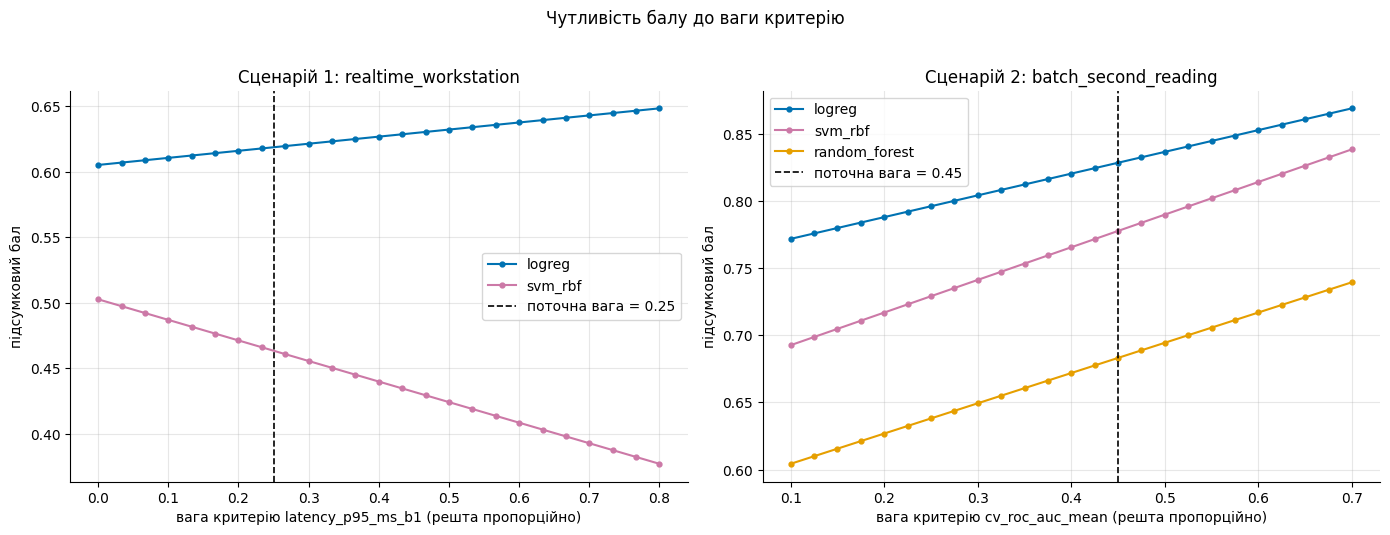

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, sens, rk, cur, xl, title in (
        (axes[0], sens1, ranking1, cfg1["criteria"]["latency_p95_ms_b1"]["weight"],
         "вага критерію latency_p95_ms_b1 (решта пропорційно)", "Сценарій 1: realtime_workstation"),
        (axes[1], sens2, ranking2, cfg2["criteria"]["cv_roc_auc_mean"]["weight"],
         "вага критерію cv_roc_auc_mean (решта пропорційно)", "Сценарій 2: batch_second_reading")):
    for m in rk["model"]:
        d = sens[sens["model"] == m].sort_values("weight")
        ax.plot(d["weight"], d["score"], marker="o", ms=3.5, color=MC[m], label=m)
    ax.axvline(cur, color="black", ls="--", lw=1.2, label=f"поточна вага = {cur:.2f}")
    ax.set_xlabel(xl)
    ax.set_ylabel("підсумковий бал")
    ax.set_title(title)
    ax.legend(loc="best")
fig.suptitle("Чутливість балу до ваги критерію", y=1.02)
fig.tight_layout()
save_show(fig, "09_weight_sensitivity.png")

**Інтерпретація рис. 9 і чутливості до ваг.** Сценарій 1 (вага затримки від 0 до 0,8 за 25 значень): `logreg` перемагає в усіх 25 (1-ше місце), `svm_rbf` — другий в усіх 25; відрив зростає від 0,1026 (вага 0: затримка не враховується) до 0,2713 (вага 0,8). Навіть коли затримка не важить нічого, `logreg` кращий (за $F_1$, recall, розміром, стабільністю).
Сценарій 2 (вага ROC-AUC від 0,10 до 0,70): `logreg` — 25 перемог, `svm_rbf` — 25 других місць, `random_forest` — 25 третіх; відрив зменшується від 0,0791 (вага 0,10) до 0,0305 (вага 0,70), але залишається додатним — у граничному випадку ваги 1,0 він дорівнював би $\Delta z_{AUC}=0{,}0062$. Лінії на рис. 9 не перетинаються.
**Ваги, за яких змінюється переможець: жодної; ваги, за яких змінюється 2-ге місце: жодної.** Додаткова перевірка 20 000 випадковими векторами ваг з усього симплекса (Діріхле(1,…,1)) дала 20 000 перемог `logreg` і 20 000 других місць `svm_rbf` в обох сценаріях.
Як зазначено в розділі 7, це випливає з домінування, тож відсутність «точки перемикання» не слід читати як «ваги підібрано дуже влучно».

## 9. Чутливість до обмежень (додатково)

Ваги стійкі, тому рішення насправді визначають **жорсткі обмеження**: вони вирішують, хто взагалі допущений. Перевіримо, як рішення залежить від межі recall
(для обох сценаріїв) і від межі затримки (сценарій 1). Орієнтири нормалізації при цьому не змінюються.

In [32]:
def run_one(cfg):
    try:
        rk, rj = rank_models(results, cfg)
    except NoEligibleModelError:
        return {"n_eligible": 0, "eligible": "", "winner": "—", "backup": "—", "gap": np.nan}
    return {"n_eligible": len(rk), "eligible": ", ".join(rk["model"]), "winner": rk.loc[0, "model"],
            "backup": rk.loc[1, "model"] if len(rk) > 1 else "—",
            "gap": rk.loc[0, "score"] - rk.loc[1, "score"] if len(rk) > 1 else np.nan}


def with_limit(cfg, metric, key, value):
    c = deepcopy(cfg)
    c["constraints"][metric][key] = float(value)
    return c


recall_grid = np.round(np.arange(0.92, 0.9701, 0.005), 4)
lat_grid = [4, 5, 6, 8, 10, 12, 15, 20]
rows = []
for name, cfg in (("realtime_workstation", cfg1), ("batch_second_reading", cfg2)):
    for v in recall_grid:
        rows.append({"scenario": name, "sweep": "recall_min", "recall_min": v,
                     "latency_max": cfg["constraints"].get("latency_p95_ms_b1", cfg["constraints"].get("latency_p95_ms_b256", {})).get("max"),
                     **run_one(with_limit(cfg, "cv_recall_mean", "min", v))})
for v in lat_grid:
    rows.append({"scenario": "realtime_workstation", "sweep": "latency_max", "recall_min": 0.95, "latency_max": float(v),
                 **run_one(with_limit(cfg1, "latency_p95_ms_b1", "max", v))})
# двовимірна сітка для сценарію 1: recall_min x latency_max
for rmin in (0.92, 0.94, 0.95, 0.96, 0.97):
    for v in lat_grid:
        c = with_limit(with_limit(cfg1, "cv_recall_mean", "min", rmin), "latency_p95_ms_b1", "max", v)
        rows.append({"scenario": "realtime_workstation", "sweep": "recall_min x latency_max", "recall_min": rmin,
                     "latency_max": float(v), **run_one(c)})
csens = pd.DataFrame(rows)
csens.to_csv(RES / "constraint_sensitivity.csv", index=False)
print("Збережено results/constraint_sensitivity.csv:", len(csens), "рядків")

for name in ("realtime_workstation", "batch_second_reading"):
    print(f"\n=== {name}: зсув межі recall (інші обмеження без змін) ===")
    t = csens[(csens["scenario"] == name) & (csens["sweep"] == "recall_min")][
        ["recall_min", "n_eligible", "eligible", "winner", "backup", "gap"]]
    display(t.set_index("recall_min").round(4))

Збережено results/constraint_sensitivity.csv: 70 рядків

=== realtime_workstation: зсув межі recall (інші обмеження без змін) ===


,n_eligible,eligible,winner,backup,gap
recall_min,,,,,
0.920,4,"logreg, svm_rbf, knn, tree",logreg,svm_rbf,0.1553
0.925,4,"logreg, svm_rbf, knn, tree",logreg,svm_rbf,0.1553
0.930,3,"logreg, svm_rbf, tree",logreg,svm_rbf,0.1553
0.935,3,"logreg, svm_rbf, tree",logreg,svm_rbf,0.1553
0.940,2,"logreg, svm_rbf",logreg,svm_rbf,0.1553
0.945,2,"logreg, svm_rbf",logreg,svm_rbf,0.1553
0.950,2,"logreg, svm_rbf",logreg,svm_rbf,0.1553
0.955,2,"logreg, svm_rbf",logreg,svm_rbf,0.1553
0.960,1,logreg,logreg,—,NaN



=== batch_second_reading: зсув межі recall (інші обмеження без змін) ===


,n_eligible,eligible,winner,backup,gap
recall_min,,,,,
0.920,5,"logreg, svm_rbf, hist_gb, knn, random_forest",logreg,svm_rbf,0.0508
0.925,5,"logreg, svm_rbf, hist_gb, knn, random_forest",logreg,svm_rbf,0.0508
0.930,4,"logreg, svm_rbf, hist_gb, random_forest",logreg,svm_rbf,0.0508
0.935,4,"logreg, svm_rbf, hist_gb, random_forest",logreg,svm_rbf,0.0508
0.940,4,"logreg, svm_rbf, hist_gb, random_forest",logreg,svm_rbf,0.0508
0.945,4,"logreg, svm_rbf, hist_gb, random_forest",logreg,svm_rbf,0.0508
0.950,3,"logreg, svm_rbf, random_forest",logreg,svm_rbf,0.0508
0.955,3,"logreg, svm_rbf, random_forest",logreg,svm_rbf,0.0508
0.960,1,logreg,logreg,—,NaN


In [33]:
print("=== realtime_workstation: зсув межі затримки (recall >= 0.95) ===")
t = csens[csens["sweep"] == "latency_max"][["latency_max", "n_eligible", "eligible", "winner", "backup", "gap"]]
display(t.set_index("latency_max").round(4))

print("=== realtime_workstation: переможець / кількість допущених у площині (recall_min, latency_max) ===")
t2 = csens[csens["sweep"] == "recall_min x latency_max"].copy()
t2["клітинка"] = t2["winner"] + " (" + t2["n_eligible"].astype(str) + ")"
display(t2.pivot(index="recall_min", columns="latency_max", values="клітинка"))

=== realtime_workstation: зсув межі затримки (recall >= 0.95) ===


,n_eligible,eligible,winner,backup,gap
latency_max,,,,,
4.0,0,,—,—,NaN
5.0,1,logreg,logreg,—,NaN
6.0,1,logreg,logreg,—,NaN
8.0,2,"logreg, svm_rbf",logreg,svm_rbf,0.1553
10.0,2,"logreg, svm_rbf",logreg,svm_rbf,0.1553
12.0,2,"logreg, svm_rbf",logreg,svm_rbf,0.1553
15.0,2,"logreg, svm_rbf",logreg,svm_rbf,0.1553
20.0,2,"logreg, svm_rbf",logreg,svm_rbf,0.1553


=== realtime_workstation: переможець / кількість допущених у площині (recall_min, latency_max) ===


latency_max,4.0,5.0,6.0,8.0,10.0,12.0,15.0,20.0
recall_min,,,,,,,,
0.92,— (0),logreg (2),logreg (3),logreg (4),logreg (4),logreg (4),logreg (5),logreg (5)
0.94,— (0),logreg (1),logreg (1),logreg (2),logreg (2),logreg (2),logreg (3),logreg (3)
0.95,— (0),logreg (1),logreg (1),logreg (2),logreg (2),logreg (2),logreg (2),logreg (2)
0.96,— (0),logreg (1),logreg (1),logreg (1),logreg (1),logreg (1),logreg (1),logreg (1)
0.97,— (0),— (0),— (0),— (0),— (0),— (0),— (0),— (0)


In [34]:
# скільки злоякісних (з 170) пропускає кожна модель в CV і яка межа recall їх відсікає
tbl = pd.DataFrame({"FN з 170": fn_tbl["FN усього"], "recall": fn_tbl["recall (з 170)"]})
tbl["межа 0.95 допускає ≤ FN"] = int(np.floor(0.05 * 170 + 1e-9))
tbl["проходить recall ≥ 0.95"] = tbl["recall"] >= 0.95
display(tbl.sort_values("FN з 170"))
print(f"Межа 0.95 на 170 позитивних = {0.05 * 170:.1f} пропущених: допускається не більше 8 (recall 0.9529), 9 вже не проходить (0.9471).")

,FN з 170,recall,межа 0.95 допускає ≤ FN,проходить recall ≥ 0.95
model,,,,
logreg,6,0.9647,8,True
svm_rbf,7,0.9588,8,True
random_forest,7,0.9588,8,True
hist_gb,9,0.9471,8,False
tree,11,0.9353,8,False
knn,12,0.9294,8,False


Межа 0.95 на 170 позитивних = 8.5 пропущених: допускається не більше 8 (recall 0.9529), 9 вже не проходить (0.9471).


**Висновок.** Переможець `logreg` не змінюється за жодних значень порогів, за яких взагалі є допущені моделі, змінюється лише *склад* допущеної множини й наявність резервної.
**Recall.** У сценарії 1 множина зменшується з 4 моделей (`recall` ≥ 0,92–0,925: `logreg`, `svm_rbf`, `knn`, `tree`) до 3 (0,93–0,935: без `knn`), до 2 (0,94–0,955) і до 1 (0,96: пройшла лише `logreg`; `svm_rbf` і `random_forest` мають 0,9588 < 0,96 — **резервної немає**); при 0,965 і 0,97 допущених немає зовсім (recall `logreg` 0,9647), і `rank_models` піднімає `NoEligibleModelError`, а не обирає «найменш погану».
У сценарії 2 множина: 5 моделей (0,92–0,925, з `hist_gb` і `knn`), 4 (0,93–0,945: без `knn`; `hist_gb` допущена, бо її recall 0,9471 ≥ 0,945), 3 (0,95–0,955: без `hist_gb`), 1 (0,96), 0 (≥ 0,965). Відхилення `hist_gb` визначає різниця в **1–2 об'єкти**: вона пропускає 9 злоякісних із 170 (recall 0,9471), а межа 0,95 допускає не більше 8 (8,5 за арифметикою);
`svm_rbf` і `random_forest` пропускають по 7, `logreg` — 6. Це на рівні шуму (1 FN = 0,0059 середнього recall, стандартна похибка recall `hist_gb` — 0,006), тож твердо відхиляти `hist_gb` «за recall» можна лише тому, що межа така задана заздалегідь, а не тому, що модель доведено гірша.
**Затримка (сценарій 1).** За межі 4 мс допущених немає (`logreg` має $p95=4{,}07$ мс), 5–6 мс — лише `logreg`, від 8 мс — `logreg` і `svm_rbf` (6,89 мс); межа 10 → 20 мс допущену множину не змінює, бо `hist_gb` додатково відсікається за recall, а `random_forest` (91,94 мс) лежить далеко. Площина «recall × затримка»: `hist_gb` допускається лише при recall ≤ 0,945 *і* межі затримки ≥ 15 мс (у сітці; фактично потрібно > 12,19 мс) (там допущено `logreg`, `svm_rbf`, `hist_gb`); переможець скрізь той самий.
Практична порада: межа 4 або 4,5 мс для `logreg` була б ризикованою — розкид $p95$ по проходах (2,13–4,56 мс) вже перетинає її; бажано мати запас до межі (тут 2,5× до 10 мс).

## 10. Фіксовані орієнтири проти min-max

Чому `worst`/`best` задано в конфігурації з названих джерел, а не береться мін/макс серед допущених моделей? Бо min-max робить бал **залежним від набору кандидатів**:
додавання чи вилучення моделі змінює шкалу для всіх, і бали вже наявних моделей змінюються без жодної зміни їхніх метрик. Покажемо це на сценарії 2 двома способами:
(А) природна зміна допущеної множини при послабленні межі recall; (Б) конкретна **інверсія порядку** двох моделей під впливом третьої.

In [35]:
def minmax_scores(elig_df, cfg):
    # бал за min-max нормалізацією серед допущених (для порівняння; в інструменті НЕ використовується)
    score = pd.Series(0.0, index=elig_df["model"])
    for c, spec in cfg["criteria"].items():
        v = elig_df.set_index("model")[c]
        lo, hi = v.min(), v.max()
        z = (v - lo) / (hi - lo) if hi > lo else pd.Series(0.0, index=v.index)
        score += spec["weight"] * (1 - z if spec["direction"] == "minimize" else z)
    return score


def both_scores(cfg):
    rk, _ = rank_models(results, cfg)                     # фіксовані орієнтири
    elig = results[results["model"].isin(rk["model"])]
    return rk.set_index("model")["score"], minmax_scores(elig, cfg)


# (А) послаблюємо межу recall: допущена множина росте (0.95 -> 0.94 -> 0.92)
cols = {}
for rmin in (0.95, 0.94, 0.92):
    fx, mm = both_scores(with_limit(cfg2, "cv_recall_mean", "min", rmin))
    cols[f"fixed, recall≥{rmin}"] = fx
    cols[f"min-max, recall≥{rmin}"] = mm
tblA = pd.DataFrame(cols).reindex(["logreg", "svm_rbf", "random_forest", "hist_gb", "knn"])
print("(А) Бал моделей сценарію 2 за різних допущених множин (NaN = модель не допущена):")
display(tblA.round(4))
fixed_cols = [c for c in tblA.columns if c.startswith("fixed")]
for m in ("logreg", "svm_rbf", "random_forest"):
    vals = tblA.loc[m, fixed_cols].to_numpy(dtype=float)
    assert np.allclose(vals, vals[0], atol=1e-12)
print("Фіксовані орієнтири: бали logreg, svm_rbf, random_forest однакові для всіх трьох допущених множин: True")
print("Min-max: бал svm_rbf =", tblA.loc["svm_rbf", [c for c in tblA.columns if c.startswith("min-max")]].round(4).tolist())

(А) Бал моделей сценарію 2 за різних допущених множин (NaN = модель не допущена):

,"fixed, recall≥0.95","min-max, recall≥0.95","fixed, recall≥0.94","min-max, recall≥0.94","fixed, recall≥0.92","min-max, recall≥0.92"
model,,,,,,
logreg,0.8284,1.0000,0.8284,1.0000,0.8284,0.9999
svm_rbf,0.7776,0.7046,0.7776,0.7046,0.7776,0.7496
random_forest,0.6832,0.0000,0.6832,0.0000,0.6832,0.1342
hist_gb,NaN,NaN,0.7508,0.4596,0.7508,0.5427
knn,NaN,NaN,NaN,NaN,0.7014,0.2320


Фіксовані орієнтири: бали logreg, svm_rbf, random_forest однакові для всіх трьох допущених множин: True
Min-max: бал svm_rbf = [0.7046, 0.7046, 0.7496]


In [36]:
# (Б) інверсія порядку: послаблюємо recall >= 0.92 і F1 >= 0.90 (допускаємо tree і knn) та обмежуємо час навчання: <= 1 с (random_forest 1.37 с поза) або <= 2 с (в наборі)
def relaxed(fit_max):
    c = with_limit(with_limit(cfg2, "cv_recall_mean", "min", 0.92), "cv_f1_mean", "min", 0.90)
    c["constraints"]["fit_time_s"] = {"max": float(fit_max)}
    return c


rows = {}
for fit_max in (1.0, 2.0):
    fx, mm = both_scores(relaxed(fit_max))
    rows[f"fixed, fit≤{fit_max}с"] = fx
    rows[f"min-max, fit≤{fit_max}с"] = mm
    rows[f"місце fixed, fit≤{fit_max}с"] = fx.rank(ascending=False)
    rows[f"місце min-max, fit≤{fit_max}с"] = mm.rank(ascending=False)
tblB = pd.DataFrame(rows).reindex(ORDER)
display(tblB.round(4))

fx1, mm1 = both_scores(relaxed(1.0))
fx2, mm2 = both_scores(relaxed(2.0))
print("Допущені при fit<=1 с:", sorted(fx1.index), "| при fit<=2 с:", sorted(fx2.index))
print(f"knn проти hist_gb, фіксовані орієнтири:  fit<=1 с: {fx1['knn']:.4f} vs {fx1['hist_gb']:.4f} (кращий: {'knn' if fx1['knn'] > fx1['hist_gb'] else 'hist_gb'});"
      f" fit<=2 с: {fx2['knn']:.4f} vs {fx2['hist_gb']:.4f} (кращий: {'knn' if fx2['knn'] > fx2['hist_gb'] else 'hist_gb'})")
print(f"knn проти hist_gb, min-max:             fit<=1 с: {mm1['knn']:.4f} vs {mm1['hist_gb']:.4f} (кращий: {'knn' if mm1['knn'] > mm1['hist_gb'] else 'hist_gb'});"
      f" fit<=2 с: {mm2['knn']:.4f} vs {mm2['hist_gb']:.4f} (кращий: {'knn' if mm2['knn'] > mm2['hist_gb'] else 'hist_gb'})")

,"fixed, fit≤1.0с","min-max, fit≤1.0с","місце fixed, fit≤1.0с","місце min-max, fit≤1.0с","fixed, fit≤2.0с","min-max, fit≤2.0с","місце fixed, fit≤2.0с","місце min-max, fit≤2.0с"
model,,,,,,,,
logreg,0.8284,0.9996,1.0,1.0,0.8284,0.9999,1.0,1.0
tree,0.3390,0.0991,5.0,5.0,0.3390,0.0997,6.0,6.0
knn,0.7014,0.7807,4.0,3.0,0.7014,0.7807,4.0,4.0
svm_rbf,0.7776,0.8822,2.0,2.0,0.7776,0.8941,2.0,2.0
random_forest,NaN,NaN,NaN,NaN,0.6832,0.6334,5.0,5.0
hist_gb,0.7508,0.7621,3.0,4.0,0.7508,0.8309,3.0,3.0


Допущені при fit<=1 с: ['hist_gb', 'knn', 'logreg', 'svm_rbf', 'tree'] | при fit<=2 с: ['hist_gb', 'knn', 'logreg', 'random_forest', 'svm_rbf', 'tree']
knn проти hist_gb, фіксовані орієнтири:  fit<=1 с: 0.7014 vs 0.7508 (кращий: hist_gb); fit<=2 с: 0.7014 vs 0.7508 (кращий: hist_gb)
knn проти hist_gb, min-max:             fit<=1 с: 0.7807 vs 0.7621 (кращий: knn); fit<=2 с: 0.7807 vs 0.8309 (кращий: hist_gb)


**Висновок.** (А) За фіксованих орієнтирів бали `logreg` (0,8284), `svm_rbf` (0,7776) і `random_forest` (0,6832) однакові для будь-якої допущеної множини — 3, 4 чи 5 моделей; бал залежить лише від метрик самої моделі й конфігурації. Під min-max той самий `svm_rbf` отримує 0,7046 (множини з 3 і 4 моделей) і 0,7496 (після додавання `knn`);
`random_forest` — 0,0000, а потім 0,1342; `hist_gb` — 0,7508 за фіксованими орієнтирами проти 0,4596 і 0,5427 під min-max. Бал під min-max — це «місце всередині конкретної групи», а не «наскільки добре відносно вимог».
(Б) Інверсія порядку: за обмежень «recall ≥ 0,92, $F_1$ ≥ 0,90, час навчання ≤ 1 с» допущені `logreg`, `tree`, `knn`, `svm_rbf`, `hist_gb`; під min-max `knn` (0,7807) випереджає `hist_gb` (0,7621). Підняття межі часу навчання до 2 с додає `random_forest` — і порядок змінюється на протилежний: `hist_gb` 0,8309 > `knn` 0,7807, хоча
метрики `knn` і `hist_gb` не змінились. Причина: `random_forest` (навчання 1,37 с) розтягує шкалу `fit_time_s`, і повільніше навчання `hist_gb` (0,44 с) штрафується значно слабше. За фіксованих орієнтирів `knn` (0,7014) < `hist_gb` (0,7508) завжди.
Ціна фіксованих орієнтирів: їх треба обґрунтувати й підтримувати (вони — теж припущення), а значення поза орієнтирами обрізаються до 0/1 і перестають розрізнятись. Але вимога «бал не залежить від випадкового складу групи» для інженерного рішення важливіша.

## 11. Автоматичні тести (завдання 13)

Модульні тести (`tests/test_model_selector.py`) перевіряють логіку відбору на малих ручних таблицях — без повторного навчання ML-моделей: нормалізацію maximize/minimize,
значення поза орієнтирами, точну межу обмеження, вилучення непридатної моделі, неправильну суму ваг, відсутню метрику, відсутність допущених моделей, однакові бали, `reweight`,
збереження. `tests/test_artifacts.py` перевіряє цілісність реальних артефактів (завантаження збереженого pipeline, узгодженість рейтингу й JSON).
`unittest` пише у **stderr** — вивід нижче це нормальний звіт, надрукований через `print`.

In [37]:
proc = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"], cwd=ROOT,
                      capture_output=True, text=True, encoding="utf-8", errors="replace",
                      env={**__import__("os").environ, "PYTHONUTF8": "1", "PYTHONDONTWRITEBYTECODE": "1"})
print("returncode =", proc.returncode)
lines = proc.stderr.strip().splitlines()
print("stdout підпроцесу:", repr(proc.stdout.strip()) if proc.stdout.strip() else "(порожній)")
print(f"Останні рядки звіту unittest (stderr), усього {len(lines)} рядків:\n")
print("\n".join(lines[-45:]))
assert proc.returncode == 0

returncode = 0
stdout підпроцесу: (порожній)
Останні рядки звіту unittest (stderr), усього 31 рядків:

test_saved_models_exist_for_all_candidates (test_artifacts.BenchmarkResultsTests.test_saved_models_exist_for_all_candidates) ... ok
test_six_unique_rows_without_nan (test_artifacts.BenchmarkResultsTests.test_six_unique_rows_without_nan) ... ok
test_primary_equals_first_ranking_row (test_artifacts.SelectionTests.test_primary_equals_first_ranking_row) ... ok
test_ranking_and_rejected_partition_all_models (test_artifacts.SelectionTests.test_ranking_and_rejected_partition_all_models) ... ok
test_selected_pipeline_loads_and_predicts_on_raw_rows (test_artifacts.SelectionTests.test_selected_pipeline_loads_and_predicts_on_raw_rows) ... ok
test_all_violations_are_listed (test_model_selector.ConstraintTests.test_all_violations_are_listed) ... ok
test_bounds_are_inclusive (test_model_selector.ConstraintTests.test_bounds_are_inclusive) ... ok
test_ineligible_model_removed_with_all_reasons (test_m

**Висновок.** `returncode = 0`, усі 26 тестів пройшли менш ніж за секунду: 21 модульний у `test_model_selector.py` (на малих ручних таблицях, без навчання моделей) і 5 тестів цілісності артефактів у `test_artifacts.py`.
Усі десять обов'язкових пунктів завдання покрито: нормалізація maximize / minimize (`test_maximize_normalization`, `test_minimize_normalization`), значення поза орієнтирами (`test_clipping_outside_anchors`), точна межа (`test_bounds_are_inclusive`), вилучення непридатної моделі з усіма причинами (`test_ineligible_model_removed_with_all_reasons`),
неправильна сума ваг (`test_wrong_weight_sum`), відсутня метрика (`test_missing_metric_column`), відсутність допущених (`test_no_eligible_models`), однакові бали (`test_identical_scores_tie_break_by_name`), завантаження збереженого pipeline (`test_selected_pipeline_loads_and_predicts_on_raw_rows`).
Рядки вигляду `... ok` — штатний вивід `unittest -v` у stderr підпроцесу, не помилки.

## 12. Фіксація рішення до відкриття test (завдання 14)

Перш ніж торкнутись тестової частини, у `results/decision_record.json` фіксуємо: основну й резервну моделі кожного сценарію, версії конфігурацій, очікуваний діапазон основної метрики,
відомі ризики й умови перевибору, а також контрольні суми всіх вхідних файлів рішення (щоб після test можна було показати, що нічого не змінено).
Основна метрика — $F_1$ (найбільша вага критеріїв сценарію 1 та умова сценарію 2); recall — жорстка межа.

In [38]:
assert not TEST_OPENED, "decision_record має бути записаний ДО відкриття test"


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


sel_files = {sc: json.loads((RES / f"selection_{sc}.json").read_text(encoding="utf-8"))
             for sc in ("realtime_workstation", "batch_second_reading")}
primary_name = sel_files["realtime_workstation"]["primary"]["model"]
fm = fold_df[fold_df["model"] == primary_name]
r_ = res.loc[primary_name]


def rng_of(mean, std, lo, hi, cap=1.0):
    return {"cv_mean": float(mean), "cv_std": float(std),
            "mean_pm_2std": [float(mean - 2 * std), float(min(cap, mean + 2 * std))],
            "fold_min_max": [float(lo), float(hi)]}


frozen = {
    "configs/realtime_workstation.json": sha256(ROOT / "configs" / "realtime_workstation.json"),
    "configs/batch_second_reading.json": sha256(ROOT / "configs" / "batch_second_reading.json"),
    "results/benchmark_results.csv": sha256(RES / "benchmark_results.csv"),
    "results/fold_results.csv": sha256(RES / "fold_results.csv"),
    "results/selected_realtime_workstation.joblib": sha256(RES / "selected_realtime_workstation.joblib"),
    "results/backup_realtime_workstation.joblib": sha256(RES / "backup_realtime_workstation.joblib"),
    "results/selected_batch_second_reading.joblib": sha256(RES / "selected_batch_second_reading.joblib"),
    "results/backup_batch_second_reading.joblib": sha256(RES / "backup_batch_second_reading.joblib"),
}

record = {
    "written_before_test_opened": bool(not TEST_OPENED),
    "protocol": {"split": "train_test_split(test_size=0.2, stratify, random_state=42)", "cv": meta["cv"],
                 "threshold": THRESHOLD, "n_train": int(n_train), "n_test": int(n_test),
                 "candidates": list(CANDIDATES), "candidates_fixed": True},
    "scenarios": {
        sc: {"config": f"configs/{sc}.json", "config_version": c["version"],
             "primary": s["primary"], "backup": s["backup"], "score_gap": s["score_gap"],
             "rejected": s["rejected"]}
        for sc, c, s in (("realtime_workstation", cfg1, sel_files["realtime_workstation"]),
                         ("batch_second_reading", cfg2, sel_files["batch_second_reading"]))},
    "expected_primary_metrics": {
        "model": primary_name,
        "main_metric": "f1 (поріг 0.5)",
        "f1": rng_of(r_["cv_f1_mean"], r_["cv_f1_std"], fm["f1"].min(), fm["f1"].max()),
        "recall": rng_of(r_["cv_recall_mean"], r_["cv_recall_std"], fm["recall"].min(), fm["recall"].max()),
        "note": "std - розкид F1/recall між фолдами по 91 зразку; тест (114 зразків) має порівнянний масштаб шуму, тому діапазон mean ± 2·std",
        "latency_p95_ms_b1_expected": {"pooled": float(r_["latency_p95_ms_b1"]),
                                       "per_pass_min_max": [float(passes.loc[primary_name, "min_pass"]),
                                                            float(passes.loc[primary_name, "max_pass"])],
                                       "machine_dependent": True},
    },
    "known_risks": [
        "Затримка вимірювалась на одній машині (i5-1035G1, 1 потік) і шумна: p95 різних проходів різниться від 1.25 до 2.14 раза; "
        "для hist_gb вона на межі 10 мс (проходи 13.96 / 8.05 / 11.57 мс), для logreg і svm_rbf межа не порушується в жодному проході.",
        "Межа recall 0.95 вирішується 1-2 об'єктами з 170 позитивних у CV: hist_gb пропускає 9 (recall 0.9471), svm_rbf і random_forest - по 7, logreg - 6.",
        "Тестова частина вже використовувалась у ПР 1-4, тому вона не є свіжою для курсу в цілому; в цій роботі до розділу 13 її не відкривали.",
        "Ваги й орієнтири нормалізації - сценарні припущення; рішення стійке до ваг лише тому, що logreg домінує за Парето в обох сценаріях.",
        "Різниці F1 між другим і п'ятим місцем (<0.01) менші за розкид між фолдами; відрив logreg від svm_rbf за F1 - 0.0115 при std ≈ 0.015-0.019.",
        "Навчальний набір (569 зразків, один центр); це не клінічна валідація.",
    ],
    "reselection_conditions": [
        "Зміна заліза/середовища виконання (CPU, кількість потоків, версія Python/scikit-learn) - повторити run_benchmark.py і select_model.py.",
        "Зміна обмежень або ваг у конфігурації (нова версія конфігурації) або нова ціна помилок.",
        "Поява нового кандидата або зміна гіперпараметрів кандидатів.",
        "Дрейф даних (інший прилад/протокол) або нова навчальна вибірка; суттєве падіння recall у моніторингу.",
        "Якщо p95 затримки обраної моделі на цільовому залізі наближається до 10 мс (сценарій 1) - перевибір.",
    ],
    "frozen_inputs_sha256": frozen,
}
(RES / "decision_record.json").write_text(json.dumps(record, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(record, ensure_ascii=False, indent=2))

{
  "written_before_test_opened": true,
  "protocol": {
    "split": "train_test_split(test_size=0.2, stratify, random_state=42)",
    "cv": {
      "type": "StratifiedKFold",
      "n_splits": 5,
      "shuffle": true,
      "random_state": 42
    },
    "threshold": 0.5,
    "n_train": 455,
    "n_test": 114,
    "candidates": [
      "logreg",
      "tree",
      "knn",
      "svm_rbf",
      "random_forest",
      "hist_gb"
    ],
    "candidates_fixed": true
  },
  "scenarios": {
    "realtime_workstation": {
      "config": "configs/realtime_workstation.json",
      "config_version": "1.0.0",
      "primary": {
        "model": "logreg",
        "score": 0.6185877501003367,
        "file": "selected_realtime_workstation.joblib"
      },
      "backup": {
        "model": "svm_rbf",
        "score": 0.4632957945732641,
        "file": "backup_realtime_workstation.joblib"
      },
      "score_gap": 0.15529195552707264,
      "rejected": [
        {
          "model": "hist_gb",
  

**Коментар.** Запис створено в одній сесії *до* кроку розділу 13 (`written_before_test_opened = true`, прапорець `TEST_OPENED` ще `False`); він містить обох переможців (основна `logreg` — для обох сценаріїв один і той самий артефакт; резервна `svm_rbf`), версії конфігурацій (обидві 1.0.0) і SHA-256 вхідних файлів.
**Очікування для основної моделі:** $F_1$ — середнє 0,9703, $\pm2\sigma$ = [0,940; 1,0] (верхню межу 1,0005 обрізано до 1,0), по фолдах 0,954–0,986; recall — середнє 0,9647, $\pm2\sigma$ = [0,900; 1,0], по фолдах 0,912–1,0. Діапазон широкий, бо фолд — лише 91 зразок (34 злоякісних), а test (114 зразків, 42 злоякісних) має схожий масштаб шуму.
Затримка ($p95$ 4,07 мс; 2,13–4,56 мс по проходах) в очікування якості не входить і залежить від машини. Відомі ризики й умови перевибору записано в JSON — головні: межа затримки шумна, межа recall вирішується 1–2 об'єктами, test уже використовувався у ПР 1–4.

## 13. Одноразова перевірка на test (завдання 15)

Тут тестова частина відкривається **один раз**. Застосовується один збережений pipeline — основна модель (`selected_realtime_workstation.joblib`); у сценарії 2 основна модель та сама,
тож перевіряємо, що файли ідентичні. **Резервну модель на test не оцінюємо** — це був би другий перегляд тесту. Поріг 0,5 (зафіксований у розділі 3).
Ваги, межі й кандидати **не змінюються** після цього кроку в межах цієї версії експерименту (конфігурації v1.0.0).

In [39]:
# контрольні суми вхідних файлів рішення не змінились з моменту decision_record.json
rec = json.loads((RES / "decision_record.json").read_text(encoding="utf-8"))
assert rec["written_before_test_opened"] is True
for rel, h in rec["frozen_inputs_sha256"].items():
    assert sha256(ROOT / rel) == h, rel
print("Усі вхідні файли рішення (конфігурації, benchmark, моделі) збігаються з decision_record.json: True")

# основна модель обох сценаріїв - один і той самий артефакт
f_rt = RES / "selected_realtime_workstation.joblib"
f_bt = RES / "selected_batch_second_reading.joblib"
print("selected_realtime == selected_batch (побайтово):", f_rt.read_bytes() == f_bt.read_bytes())

# ---- ТЕСТ ВІДКРИВАЄТЬСЯ ТУТ, один раз ----
assert not TEST_OPENED
TEST_OPENED = True
model = joblib.load(f_rt)
proba_test = model.predict_proba(data.X_test)[:, 1]
proba_test_b = joblib.load(f_bt).predict_proba(data.X_test)[:, 1]
assert np.array_equal(proba_test, proba_test_b)
pred_test = (proba_test >= THRESHOLD).astype(int)
yt = data.y_test.to_numpy()

tn, fp, fn, tp = confusion_matrix(yt, pred_test, labels=[0, 1]).ravel()
test_metrics = {
    "f1": f1_score(yt, pred_test), "recall": recall_score(yt, pred_test), "precision": precision_score(yt, pred_test),
    "roc_auc": roc_auc_score(yt, proba_test), "balanced_accuracy": balanced_accuracy_score(yt, pred_test)}
print("TEST_OPENED =", TEST_OPENED, "| модель:", primary_name, "| поріг:", THRESHOLD, "| n_test =", len(yt),
      "| злоякісних у test:", int(yt.sum()))
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
print({k: round(float(v), 4) for k, v in test_metrics.items()})

Усі вхідні файли рішення (конфігурації, benchmark, моделі) збігаються з decision_record.json: True
selected_realtime == selected_batch (побайтово): True
TEST_OPENED = True | модель: logreg | поріг: 0.5 | n_test = 114 | злоякісних у test: 42
TN = 71, FP = 1, FN = 1, TP = 41
{'f1': 0.9762, 'recall': 0.9762, 'precision': 0.9762, 'roc_auc': 0.9954, 'balanced_accuracy': 0.9812}


In [40]:
# порівняння з CV-очікуванням, зафіксованим у decision_record.json
rows = []
for k, cv_name in (("f1", "f1"), ("recall", "recall")):
    e = rec["expected_primary_metrics"][k]
    lo, hi = e["mean_pm_2std"]
    rows.append({"метрика": k, "CV mean": e["cv_mean"], "CV std": e["cv_std"], "mean±2std: від": lo, "до": hi,
                 "фолди: min": e["fold_min_max"][0], "max": e["fold_min_max"][1],
                 "test": test_metrics[k], "у межах mean±2std": lo <= test_metrics[k] <= hi,
                 "у межах min..max фолдів": e["fold_min_max"][0] <= test_metrics[k] <= e["fold_min_max"][1]})
for k, cvcol, stdcol in (("precision", "cv_precision_mean", None), ("roc_auc", "cv_roc_auc_mean", "cv_roc_auc_std"),
                         ("balanced_accuracy", "cv_balanced_accuracy_mean", None)):
    sub = fm[k if k != "balanced_accuracy" else "balanced_accuracy"]
    m, s = sub.mean(), sub.std(ddof=1)
    rows.append({"метрика": k, "CV mean": m, "CV std": s, "mean±2std: від": m - 2 * s, "до": min(1.0, m + 2 * s),
                 "фолди: min": sub.min(), "max": sub.max(), "test": test_metrics[k],
                 "у межах mean±2std": (m - 2 * s) <= test_metrics[k] <= m + 2 * s,
                 "у межах min..max фолдів": sub.min() <= test_metrics[k] <= sub.max()})
cmp_test = pd.DataFrame(rows).set_index("метрика")
display(cmp_test.round(4))

n_pos_test = int(yt.sum())
ci_rec = binomtest(int(tp), n_pos_test).proportion_ci(confidence_level=0.95, method="wilson")
ci_pre = binomtest(int(tp), int(tp + fp)).proportion_ci(confidence_level=0.95, method="wilson")
print(f"Recall: {tp}/{n_pos_test} = {tp / n_pos_test:.4f}, 95 % інтервал Вілсона [{ci_rec.low:.3f}; {ci_rec.high:.3f}]; "
      f"один пропущений об'єкт змінює recall на {1 / n_pos_test:.4f}")
print(f"Precision: {tp}/{tp + fp} = {tp / (tp + fp):.4f}, 95 % інтервал Вілсона [{ci_pre.low:.3f}; {ci_pre.high:.3f}]")
max_fn = int(np.floor(0.05 * n_pos_test + 1e-9))
print("Межа recall >= 0.95 (задана для CV) на test:", "дотримано" if test_metrics["recall"] >= 0.95 else "не дотримано",
      f"| на {n_pos_test} позитивних допустимо не більше {max_fn} FN (recall {1 - max_fn / n_pos_test:.4f}), фактично FN = {fn}")

test_json = {
    "model": primary_name, "scenario_config_versions": {"realtime_workstation": cfg1["version"], "batch_second_reading": cfg2["version"]},
    "threshold": THRESHOLD, "n_test": int(len(yt)), "n_positive": n_pos_test,
    "confusion_matrix": {"TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)},
    "metrics": {k: float(v) for k, v in test_metrics.items()},
    "recall_wilson_95": [float(ci_rec.low), float(ci_rec.high)],
    "precision_wilson_95": [float(ci_pre.low), float(ci_pre.high)],
    "cv_expectation_from": "results/decision_record.json",
    "within_mean_pm_2std": {k: bool(v) for k, v in cmp_test["у межах mean±2std"].items()},
    "opened_once": True,
    "weights_limits_candidates_changed_after_test": False,
}
(RES / "test_results.json").write_text(json.dumps(test_json, ensure_ascii=False, indent=2), encoding="utf-8")
print("Збережено results/test_results.json")

,CV mean,CV std,mean±2std: від,до,фолди: min,max,test,у межах mean±2std,у межах min..max фолдів
метрика,,,,,,,,,
f1,0.9703,0.0151,0.9401,1.0,0.9538,0.9855,0.9762,True,True
recall,0.9647,0.0322,0.9003,1.0,0.9118,1.0000,0.9762,True,True
precision,0.9770,0.0240,0.9291,1.0,0.9429,1.0000,0.9762,True,True
roc_auc,0.9959,0.0055,0.9848,1.0,0.9861,0.9990,0.9954,True,True
balanced_accuracy,0.9753,0.0140,0.9472,1.0,0.9559,0.9912,0.9812,True,True


Recall: 41/42 = 0.9762, 95 % інтервал Вілсона [0.877; 0.996]; один пропущений об'єкт змінює recall на 0.0238
Precision: 41/42 = 0.9762, 95 % інтервал Вілсона [0.877; 0.996]
Межа recall >= 0.95 (задана для CV) на test: дотримано | на 42 позитивних допустимо не більше 2 FN (recall 0.9524), фактично FN = 1
Збережено results/test_results.json


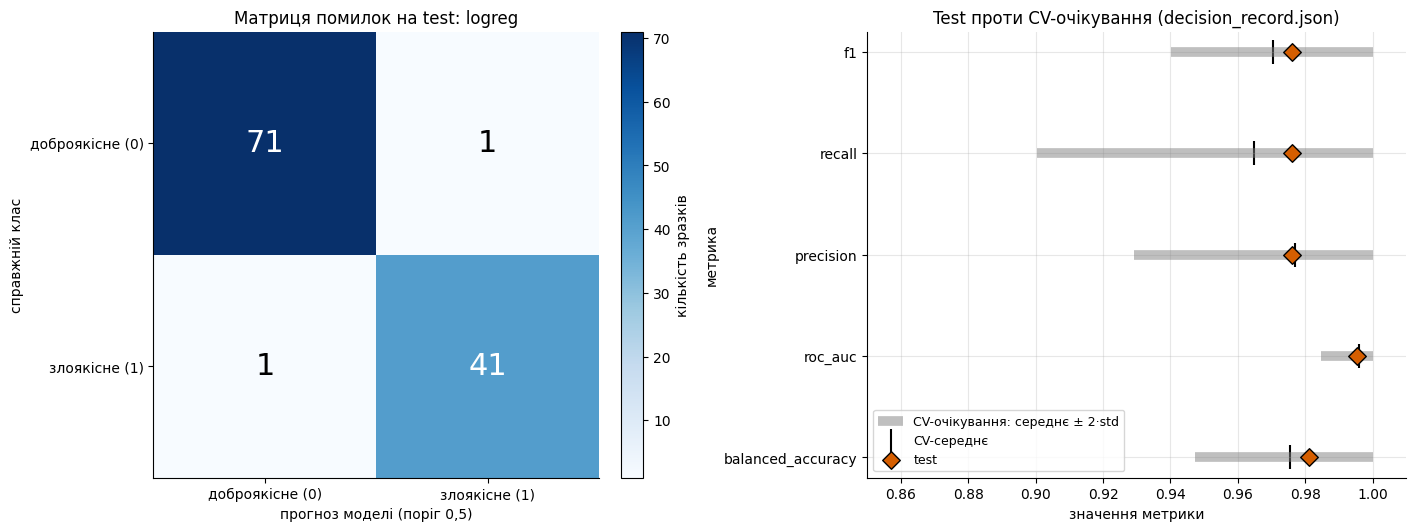

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), layout="constrained")
ax = axes[0]
cm = np.array([[tn, fp], [fn, tp]])
im = ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=22,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1])
ax.set_xticklabels(["доброякісне (0)", "злоякісне (1)"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["доброякісне (0)", "злоякісне (1)"])
ax.set_xlabel("прогноз моделі (поріг 0,5)")
ax.set_ylabel("справжній клас")
ax.set_title(f"Матриця помилок на test: {primary_name}")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="кількість зразків")

ax = axes[1]
mets = ["f1", "recall", "precision", "roc_auc", "balanced_accuracy"]
y = np.arange(len(mets))
ax.hlines(y, cmp_test.loc[mets, "mean±2std: від"], cmp_test.loc[mets, "до"], color="grey", lw=7, alpha=0.5,
          label="CV-очікування: середнє ± 2·std")
ax.scatter(cmp_test.loc[mets, "CV mean"], y, marker="|", s=300, color="black", label="CV-середнє")
ax.scatter(cmp_test.loc[mets, "test"], y, marker="D", s=80, color="#D55E00", edgecolor="black", zorder=3, label="test")
ax.set_yticks(y)
ax.set_yticklabels(mets)
ax.invert_yaxis()
ax.set_xlim(0.85, 1.01)
ax.set_xlabel("значення метрики")
ax.set_ylabel("метрика")
ax.set_title("Test проти CV-очікування (decision_record.json)")
ax.legend(loc="lower left", fontsize=9)
save_show(fig, "10_test_confusion_matrix.png")

**Інтерпретація рис. 10 і test.** Основна модель (`logreg`, поріг 0,5) на 114 тестових зразках: TN = 71, FP = 1, FN = 1, TP = 41; $F_1=0{,}9762$, recall $=0{,}9762$ (41/42), precision $=0{,}9762$ (41/42), ROC-AUC $=0{,}9954$, balanced accuracy $=0{,}9812$.
Усі п'ять метрик **у межах CV-очікування** ($\text{mean}\pm2\sigma$) і в межах min–max по фолдах: $F_1$ 0,9762 проти CV 0,9703 (+0,006, 0,4 $\sigma$); recall 0,9762 проти 0,9647; precision 0,9762 проти 0,9770; ROC-AUC 0,9954 проти 0,9959. Межа recall ≥ 0,95 на 42 позитивних допускає не більше 2 пропущених; фактично 1.
Тобто test **підтвердив CV-очікування**, але доказова сила невелика: один FN або FP змінює recall чи precision на 2,4 п. п., а 95 % інтервал Вілсона для recall (як і для precision) — [0,877; 0,996]. Крім того, test не є свіжим для курсу (використовувався в ПР 1–4), хоча вибір у цій роботі зроблено лише за CV.
Трохи вищий $F_1$ на test, ніж у CV, природний (фінальна модель навчена на 455, а не 364 зразках) і не свідчить про недооцінку. Резервну модель на test **не оцінювали** (це був би другий перегляд тесту). Ваги, межі, кандидатів і поріг після відкриття test не змінювали: SHA-256 вхідних файлів збігаються із записаними в `decision_record.json` (перевірено в коді перед кроком).

## 14. Інженерний висновок (завдання 16)

Усі межі й ваги — сценарні припущення навчальної постановки; набір даних навчальний; клінічне впровадження потребує погодження з клініцистами, валідації на незалежних даних і вимірювань на цільовому залізі.

1. **Які кандидати порушили жорсткі обмеження.** Сценарій 1: `tree` (recall 0,9353 < 0,95), `knn` (recall 0,9294 < 0,95), `hist_gb` (recall 0,9471 < 0,95 **і** $p95=12{,}19$ мс > 10 мс), `random_forest` ($p95=91{,}94$ мс > 10 мс). Сценарій 2: `tree` (recall 0,9353 та $F_1=0{,}9085<0{,}94$), `knn` (recall 0,9294), `hist_gb` (recall 0,9471). Обмеження на розмір (0,5 / 5 МБ) і на затримку пакета 256 (200 мс) **не порушила жодна** модель.
2. **Основна і резервна.** У обох сценаріях основна — `logreg` (бал 0,6186 і 0,8284), резервна — `svm_rbf` (0,4633 і 0,7776); відриви 0,1553 і 0,0508. Файли `selected_*.joblib` обох сценаріїв побайтово однакові (SHA-256 збігаються).
3. **Які критерії визначили результат.** Спершу жорсткі обмеження (recall та затримка): вони залишили 2 і 3 допущені моделі з 6. Серед допущених у сценарії 1 відрив дають затримка (50,5 %), $F_1$ (22,2 %) і recall (18,9 %); у сценарії 2 — $F_1$ (68 %) і його стабільність (25 %); ROC-AUC з найбільшою вагою 0,45 дав лише 5,5 %, бо моделі майже однакові за ним.
4. **Чи змінився переможець у сценарії 2.** Ні: `logreg` у обох. Допущені множини різні (`{logreg, svm_rbf}` проти `{logreg, svm_rbf, random_forest}`), але `logreg` домінує за Парето над усіма допущеними в обох сценаріях.
5. **Чутливість до ваг.** Рішення нечутливе: 25 + 25 значень ваги (затримка 0–0,8; ROC-AUC 0,10–0,70) та 20 000 випадкових векторів ваг — жодної зміни 1-го чи 2-го місця; найменший відрив 0,1026 (сц. 1) і 0,0305 (сц. 2). Це пояснюється домінуванням, а не вдалим добором ваг. Більш чутливе рішення — до **обмежень**: при recall ≥ 0,96 допущена лише `logreg` (резервної немає), при ≥ 0,965 — жодної.
6. **Чи підтвердив test CV-очікування.** Так: $F_1=0{,}9762$ (CV 0,9703), recall 0,9762 (41/42; CV 0,9647), precision 0,9762, ROC-AUC 0,9954, FN = 1, FP = 1; усе в межах $\text{mean}\pm2\sigma$. Доказова сила обмежена: 42 злоякісних (інтервал Вілсона для recall [0,877; 0,996]) і test не є свіжим для курсу.
7. **Що залежить від апаратного середовища.** Час навчання, $p50$/$p95$ затримки, пропускна здатність (а отже й критерії/обмеження на їх основі; на це вказує розкид $p95$ по проходах: від ×1,25 до ×2,14, `hist_gb` 8,05–13,96 мс). Не залежать від заліза (за тих самих даних, сідів і версій бібліотек): CV-метрики, recall-обмеження, розмір файлів (залежить від версії бібліотек і стиснення).
8. **Коли повторити процедуру.** Нове залізо чи потоки, нова версія Python/scikit-learn, нова навчальна вибірка або дрейф даних, зміна цін помилок, меж чи ваг (нова версія конфігурації), новий кандидат, падіння recall у моніторингу, наближення виміряного $p95$ до межі (запас до 10 мс має лишатись). Повний список — у `results/decision_record.json`.
9. **Обмеження інструмента.** (а) Профілюється лише `predict_proba` одного процесу з одним потоком на одному ноутбуці; не враховано вилучення ознак, ввід-вивід, запуск процесу, пам'ять. (б) Шість фіксованих кандидатів із гіперпараметрами з попередніх робіт, без підбору. (в) Моделі за якістю статистично нерозрізнювані (різниці $F_1$ менші за розкид між фолдами), 170 позитивних у CV: 1 FN = 0,0059 recall. (г) Ваги й орієнтири — припущення; орієнтири розміру (0,5 МБ) і часу навчання (10 с) надто широкі, критерії майже не розрізняють моделі. (д) Рейтинг — лінійна згортка з обрізанням у [0, 1]: значення за орієнтирами не розрізняються; Парето-аналіз виконано лише як перевірка, а не як основний метод. (е) Поріг 0,5 фіксований, калібрування не оцінювалось. (ж) Один спліт; test не є свіжим для курсу; клінічної валідації немає.

In [42]:
# контроль: артефакти, створені ноутбуком
for d in (FIG, RES):
    items = sorted(p for p in d.iterdir() if p.is_file() and (d == FIG or p.name in (
        "decision_record.json", "test_results.json", "constraint_sensitivity.csv",
        "sensitivity_batch_second_reading.csv", "sensitivity_realtime_workstation.csv")))
    print(f"{d.relative_to(ROOT)}/:", ", ".join(f"{p.name} ({p.stat().st_size // 1024} КБ)" for p in items))

figures/: 01_quality_vs_latency.png (66 КБ), 02_latency_distributions.png (71 КБ), 03_latency_per_pass.png (57 КБ), 04_model_size.png (43 КБ), 05_fold_scores.png (79 КБ), 06_normalized_criteria_realtime.png (39 КБ), 07_normalized_criteria_batch.png (41 КБ), 08_scenario_scores.png (50 КБ), 09_weight_sensitivity.png (101 КБ), 10_test_confusion_matrix.png (64 КБ)
results/: constraint_sensitivity.csv (6 КБ), decision_record.json (6 КБ), sensitivity_batch_second_reading.csv (3 КБ), sensitivity_realtime_workstation.csv (2 КБ), test_results.json (0 КБ)
